---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 25 (IMKSIAI)

- Yusuf Faishal Listyardi (13524014)
- Aziza Dharma Putri (13524017)
- Niko Samuel Simanjuntak (13524029)
- An-Dafa Anza Alvansyah (13524038)
- Kalyca Nathania Benedicta M. (13524071)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Cost-Sensitive Classification (Bonus)**](#12)
13. [**Visualisasi SVM 2D (Bonus)**](#13)
14. [**Optimasi SVM dengan Differential Evolution (Bonus)**](#14)
15. [**Optimasi Lanjutan SVM (Bonus)**](#15)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pesanan meninggalkan kamar kosong yang sebenarnya bisa dijual ke tamu lain. Prediksi pembatalan sejak awal membantu penginapan merencanakan *overbooking*, mengirim pengingat, dan menyusun kebijakan pembatalan.

## Aim

Membangun model klasifikasi *from scratch* yang memprediksi apakah sebuah pesanan dibatalkan (`is_canceled = 1`) atau tidak (`is_canceled = 0`).

## Metric

Leaderboard Kaggle memakai **Macro F1-score**, yaitu rata-rata F1 kelas batal dan F1 kelas tidak batal. Kedua kelas berbobot sama, sehingga model yang hanya menebak kelas mayoritas mendapat skor rendah. Seluruh validasi di notebook ini memakai metrik yang sama (`macro_f1` di `src/metrics.py`).

## Dataset

`train.csv` berisi 27.373 pesanan beserta label, `test.csv` berisi 6.844 pesanan tanpa label. Ada 17 fitur: jumlah tamu, lama menginap, paket makan, kategori kamar, jarak hari pemesanan ke kedatangan, tanggal kedatangan, kanal pemesanan, riwayat tamu, harga per malam (IDR), dan jumlah permintaan khusus. Delapan kolom memiliki *missing values*.

## Approach

1. Pisahkan `train.csv` menjadi data latih dan validasi sebelum *preprocessing*.
2. Pelajari semua statistik *preprocessing* dari data latih saja, lalu terapkan ke validasi dan test.
3. Latih model *from scratch* (`src/`). KNN memilih hyperparameter dengan *stratified 5-fold cross-validation*. Uji tiga kernel SVM dengan parameter awal pada data validasi 20%.
4. Bandingkan dengan `scikit-learn`, simpan model, dan buat submisi Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [6]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [ ]:
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modul from scratch ada di folder src/.
ROOT = Path.cwd().parent if Path.cwd().name == 'src' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from preprocessing import SVMPreprocessor, Preprocessor, drop_duplicate_rows, NUMERIC_COLS, CATEGORICAL_COLS, TARGET
from knn import KNN
from svm import SVM, differential_evolution
from metrics import (macro_f1, accuracy, confusion_matrix, f1_per_class,
                     misclassification_cost, stratified_kfold_indices)

## Settings

Paths and shared constants are kept in this class.

In [ ]:
class Settings:
    SEED       = 42
    DATA_DIR   = ROOT / 'data'
    OUTPUT_DIR = ROOT / 'output'
    MODEL_DIR  = ROOT / 'output' / 'models'
    VAL_SIZE   = 0.2
    N_FOLDS    = 5
    PLOT_COLOR = 'steelblue'
    SVM_C = 1.0
    SVM_DEGREE = 2
    SVM_TOL = 1e-3
    SVM_MAX_ITER = 1000000
    # Bobot fitur untuk jarak KNN; asal nilainya dijelaskan di bagian Improvements.
    # Key-nya adalah nama kolom di Preprocessor.
    FEATURE_WEIGHTS = {
        'log_lead_time': 1.5, 'days_before_arrival': 1.5,
        'special_requests': 1.5, 'nightly_rate_idr': 1.5,
        'meal_package': 0.5, 'room_category': 0.5,
    }

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [9]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [10]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [11]:
print(train_df.dtypes.to_string())
train_df.describe().T

id                           object
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
meal_package                 object
needs_parking               float64
room_category                object
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel              object
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
is_canceled                   int64


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


**Insights:**

- `id` dibaca sebagai teks dan tidak dipakai sebagai fitur.
- Fitur kategorikal nominal: `meal_package`, `room_category` (huruf tanpa urutan), `booking_channel`.
- Fitur biner: `needs_parking`, `is_returning_guest`. Sisanya numerik.
- `days_before_arrival` dan `nightly_rate_idr` memiliki rentang yang jauh lebih besar daripada fitur lain, sehingga model berbasis jarak memerlukan *scaling*.

## Explore Data

This part covers distributions and relationships between attributes.

Proporsi target:
is_canceled
0    0.672
1    0.328


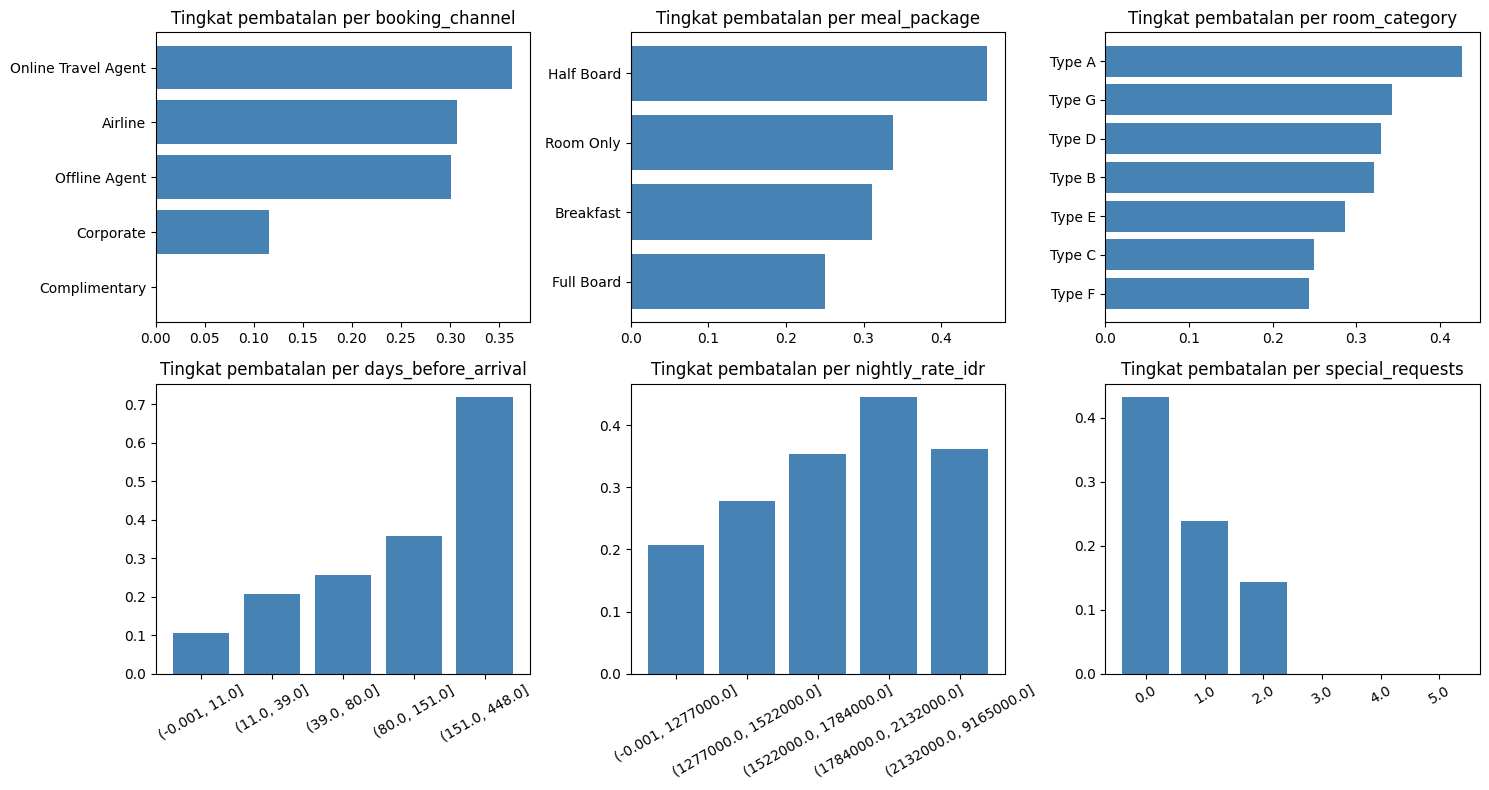

In [12]:
print('Proporsi target:')
print(train_df[TARGET].value_counts(normalize=True).round(3).to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes[0], ['booking_channel', 'meal_package', 'room_category']):
    rate = train_df.groupby(col)[TARGET].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values, color=CFG.PLOT_COLOR)
    ax.set_title(f'Tingkat pembatalan per {col}')
for ax, col in zip(axes[1], ['days_before_arrival', 'nightly_rate_idr', 'special_requests']):
    if train_df[col].nunique() > 10:
        bins = pd.qcut(train_df[col], 5, duplicates='drop')
    else:
        bins = train_df[col]
    rate = train_df.groupby(bins, observed=True)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color=CFG.PLOT_COLOR)
    ax.set_title(f'Tingkat pembatalan per {col}')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Insights:**

- Kelas tidak seimbang secara moderat: sekitar 67% tidak batal, 33% batal.
- `days_before_arrival` adalah sinyal terkuat: pesanan yang dibuat jauh hari lebih sering dibatalkan.
- `special_requests` berbanding terbalik dengan pembatalan; tamu dengan 3 permintaan atau lebih hampir tidak pernah membatalkan.
- Kanal *Complimentary* dan *Corporate* jarang batal, sedangkan *Online Travel Agent* paling sering.
- Pola-pola ini tidak linear, sehingga model seperti KNN dan *decision tree* diperkirakan lebih cocok daripada model linear.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [13]:
quality = pd.DataFrame({
    'missing_train': train_df.isna().sum(),
    'missing_test': test_df.isna().sum(),
})
print(quality[quality.sum(axis=1) > 0])

feature_cols = [c for c in train_df.columns if c != 'id']
print('\nBaris duplikat (tanpa id):', train_df.duplicated(subset=feature_cols).sum())
print('Harga 0 (komplimenter):', (train_df['nightly_rate_idr'] == 0).sum())
print('0 orang dewasa:', (train_df['num_adults'] == 0).sum())
print('0 malam menginap:', ((train_df['weekend_nights'] + train_df['weekday_nights']) == 0).sum())
dates = pd.to_datetime(dict(year=train_df.arrival_year, month=train_df.arrival_month, day=train_df.arrival_day), errors='coerce')
print('Tanggal tidak valid:', dates.isna().sum())

                     missing_train  missing_test
days_before_arrival           1123         290.0
meal_package                  1760         442.0
needs_parking                 1082         247.0
nightly_rate_idr              2038         540.0
num_adults                     809         180.0
num_children                  3035         747.0
room_category                 1002         242.0
special_requests              2500         593.0

Baris duplikat (tanpa id): 64
Harga 0 (komplimenter): 413
0 orang dewasa: 106
0 malam menginap: 64
Tanggal tidak valid: 0


**Insights:**

- Delapan kolom memiliki *missing values* sebesar 3–11%, dengan pola serupa di train dan test.
- Terdapat 64 baris duplikat. Duplikat hanya dibuang dari data latih agar validasi tetap mencerminkan data asli.
- Harga 0 sesuai deskripsi dataset (menginap komplimenter), jadi bukan kesalahan data.
- Pesanan dengan 0 orang dewasa atau 0 malam jumlahnya sedikit dan juga muncul di data test, sehingga tetap dipertahankan.
- Semua tanggal kedatangan valid.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [14]:
from sklearn.model_selection import train_test_split

train_set, val_set = train_test_split(
    train_df, test_size=CFG.VAL_SIZE, stratify=train_df[TARGET], random_state=CFG.SEED,
)
train_set = train_set.reset_index(drop=True)
val_set = val_set.reset_index(drop=True)
print(f'Train: {train_set.shape}  Validation: {val_set.shape}')
print('Proporsi batal  train: %.3f  val: %.3f' % (train_set[TARGET].mean(), val_set[TARGET].mean()))

Train: (21898, 19)  Validation: (5475, 19)
Proporsi batal  train: 0.328  val: 0.328


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [15]:
# id hanya penanda baris, sedangkan target dipisahkan saat format data.
selected_features = NUMERIC_COLS + CATEGORICAL_COLS
print(len(selected_features), 'fitur dipakai:', selected_features)

17 fitur dipakai: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'meal_package', 'room_category', 'booking_channel']


**Insights:**

Semua 17 fitur asli dipakai. Pada eksperimen awal, membuang fitur mana pun tidak menaikkan Macro F1, sedangkan semua fitur memiliki hubungan yang masuk akal dengan pembatalan.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [16]:
print(train_set[selected_features].isna().sum()[lambda s: s > 0])
print('\nMedian (dari data latih) untuk imputasi numerik:')
print(train_set[NUMERIC_COLS].median().to_string())

num_adults              636
num_children           2426
needs_parking           885
days_before_arrival     877
nightly_rate_idr       1622
special_requests       2015
meal_package           1403
room_category           810
dtype: int64

Median (dari data latih) untuk imputasi numerik:
num_adults                        2.0
num_children                      0.0
weekend_nights                    1.0
weekday_nights                    2.0
needs_parking                     0.0
days_before_arrival              57.0
arrival_year                   2024.0
arrival_month                     8.0
arrival_day                      16.0
is_returning_guest                0.0
prior_cancellations               0.0
prior_completed_bookings          0.0
nightly_rate_idr            1647000.0
special_requests                  0.0


**Insights:**

- Numerik: diisi median data latih, karena median tahan terhadap distribusi yang miring seperti `days_before_arrival`.
- Kategorikal: diisi kategori baru `Unknown`, sehingga informasi "tidak diisi" tetap ada.
- Imputasi dikerjakan di dalam `Preprocessor.fit` / `transform` (`src/preprocessing.py`) agar median hanya dihitung dari data latih.

### Duplicates

This part covers repeated records.

In [17]:
n_before = len(train_set)
train_set = drop_duplicate_rows(train_set)
print(f'Duplikat dibuang dari data latih: {n_before - len(train_set)}')

Duplikat dibuang dari data latih: 40


### Outliers

This part covers values far from the rest of the data.

In [18]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print(train_set[NUMERIC_COLS].apply(iqr_outliers).sort_values(ascending=False).head(8))

num_adults                  5916
arrival_year                3941
num_children                1613
nightly_rate_idr             886
days_before_arrival          750
needs_parking                644
is_returning_guest           545
prior_completed_bookings     477
dtype: int64


**Insights:**

- Pada kolom diskret dengan IQR = 0 (`num_adults`, `arrival_year`, `num_children`, kolom biner), aturan IQR menandai hampir semua nilai selain modus sebagai *outlier*. Aturan ini tidak cocok untuk kolom seperti itu.
- Pada kolom kontinu (`nightly_rate_idr`, `days_before_arrival`, `prior_completed_bookings`), nilai di luar batas IQR adalah nilai yang mungkin terjadi, bukan kesalahan input.
- Karena itu *outlier* dipertahankan. Efeknya pada jarak KNN dikurangi oleh standarisasi dan transformasi log pada lead time.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [19]:
# Kolom bilangan bulat yang memiliki NaN terbaca sebagai float. Ini tidak masalah karena semua fitur numerik diproses sebagai float.
for col in CATEGORICAL_COLS:
    print(col, sorted(train_set[col].dropna().unique()))

meal_package ['Breakfast', 'Full Board', 'Half Board', 'Room Only']
room_category ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G']
booking_channel ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


**Insights:**

Label kategori konsisten dan tidak ada nilai yang mustahil. Kategori yang sangat jarang (misalnya *Full Board* dengan 4 baris) digabung menjadi `Other` saat *encoding*.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [20]:
pp_demo = Preprocessor().fit(train_set)
derived_preview = Preprocessor._derive(train_set[NUMERIC_COLS].fillna(pp_demo.medians_))
derived_preview.head()

,log_lead_time,arrival_date_ordinal
0,5.963579,739181.0
1,5.726848,739193.0
2,5.117994,738795.0
3,3.401197,739221.0
4,3.332205,739015.0


**Insights:**

- `log_lead_time = log(1 + days_before_arrival)`: lead time sangat miring ke kanan; log membuat jarak antara 0 dan 30 hari lebih berarti daripada jarak antara 300 dan 330 hari.
- `arrival_date_ordinal`: tanggal kedatangan sebagai satu angka, sehingga tren waktu (tingkat batal 2023 jauh lebih rendah daripada 2024) terwakili dalam satu dimensi.
- Kedua fitur ini menaikkan Macro F1 KNN pada *cross-validation*. Fitur turunan lain yang dicoba (total malam, total tamu, harga per tamu, hari dalam minggu) tidak membantu KNN sehingga tidak dipakai.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [21]:
print('Mean dan std (dari data latih) untuk standarisasi:')
print(pd.DataFrame({'mean': pp_demo.mean_, 'std': pp_demo.std_}).round(3))

Mean dan std (dari data latih) untuk standarisasi:
                                 mean         std
num_adults                      1.852       0.512
num_children                    0.105       0.407
weekend_nights                  0.818       0.875
weekday_nights                  2.198       1.421
needs_parking                   0.029       0.169
days_before_arrival            83.873      84.245
arrival_year                 2023.820       0.384
arrival_month                   7.395       3.077
arrival_day                    15.540       8.772
is_returning_guest              0.025       0.156
prior_cancellations             0.021       0.357
prior_completed_bookings        0.139       1.627
nightly_rate_idr          1713998.445  563908.889
special_requests                0.608       0.786
log_lead_time                   3.741       1.453
arrival_date_ordinal       739029.164     139.961


**Insights:**

Standarisasi z-score dipakai untuk KNN, karena tanpa *scaling* jarak didominasi `nightly_rate_idr` (jutaan) dan `days_before_arrival` (ratusan). Kolom *one-hot* dibiarkan bernilai 0/1.

### Encoding

This part covers the numeric representation of categorical attributes.

In [22]:
for col, cats in pp_demo.categories_.items():
    print(col, '->', cats)

meal_package -> ['Breakfast', 'Half Board', 'Room Only', 'Unknown', 'Other']
room_category -> ['Type A', 'Type B', 'Type C', 'Type D', 'Type F', 'Type G', 'Unknown', 'Other']
booking_channel -> ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent', 'Other']


**Insights:**

Ketiga fitur kategorikal bersifat nominal (tidak berurutan), jadi dipakai *one-hot encoding*. *Label encoding* akan membuat KNN menganggap, misalnya, Type A lebih dekat ke Type B daripada ke Type G, padahal huruf tersebut tidak memiliki urutan.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [23]:
X_demo = pp_demo.transform(train_set)
Xc = X_demo - X_demo.mean(axis=0)
explained = np.linalg.svd(Xc, compute_uv=False) ** 2
explained_ratio = np.cumsum(explained) / explained.sum()
for n in (5, 10, 15, 20):
    print(f'{n} komponen utama menjelaskan {explained_ratio[n - 1]:.1%} variansi')

5 komponen utama menjelaskan 51.0% variansi
10 komponen utama menjelaskan 78.8% variansi
15 komponen utama menjelaskan 94.3% variansi
20 komponen utama menjelaskan 99.0% variansi


**Insights:**

Dengan hanya 35 kolom setelah *encoding*, dimensi masih kecil untuk KNN. PCA juga membutuhkan banyak komponen untuk mempertahankan sebagian besar variansi, sehingga PCA tidak dipakai pada model utama.

## Class Balance

This part covers the proportion of each class in the training data.

In [24]:
print(train_set[TARGET].value_counts().to_string())
print(train_set[TARGET].value_counts(normalize=True).round(3).to_string())

is_canceled
0    14696
1     7162
is_canceled
0    0.672
1    0.328


**Insights:**

Rasio sekitar 67:33 tergolong tidak seimbang secara moderat. Tidak dilakukan *resampling*; pada eksperimen awal, model sudah memprediksi kedua kelas dengan baik, dan menggeser *threshold* keputusan tidak menaikkan Macro F1 KNN.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [25]:
y_train = train_set[TARGET].to_numpy()
y_val = val_set[TARGET].to_numpy()
print('y_train', y_train.shape, ' y_val', y_val.shape)

y_train (21858,)  y_val (5475,)


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [26]:
preprocessor = Preprocessor(scale=True, min_category_freq=20, add_derived=True)
X_train = preprocessor.fit_transform(train_set)   # Fit hanya pada data latih.
X_val = preprocessor.transform(val_set)           # Validasi hanya ditransformasi.

print('X_train', X_train.shape, ' X_val', X_val.shape)
print('NaN tersisa:', np.isnan(X_train).sum(), np.isnan(X_val).sum())
print(preprocessor.feature_names_)

X_train (21858, 35)  X_val (5475, 35)
NaN tersisa: 0 0
['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'log_lead_time', 'arrival_date_ordinal', 'meal_package=Breakfast', 'meal_package=Half Board', 'meal_package=Room Only', 'meal_package=Unknown', 'meal_package=Other', 'room_category=Type A', 'room_category=Type B', 'room_category=Type C', 'room_category=Type D', 'room_category=Type F', 'room_category=Type G', 'room_category=Unknown', 'room_category=Other', 'booking_channel=Airline', 'booking_channel=Complimentary', 'booking_channel=Corporate', 'booking_channel=Offline Agent', 'booking_channel=Online Travel Agent', 'booking_channel=Other']


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

Implementasi: `src/knn.py` (kelas `KNN`). Jarak Euclidean, Manhattan, atau Minkowski; voting seragam atau berbobot `1/jarak`; komputasi jarak per *batch* agar memori terkendali. Bobot fitur pada jarak diterapkan di `Preprocessor(feature_weights=...)`.

In [27]:
# Tuning hyperparameter dengan stratified 5-fold CV pada data latih.
# Preprocessor di-fit ulang di setiap fold supaya fold validasi tidak bocor.
K_GRID = [5, 11, 15, 21, 31, 41]
P_GRID = [1, 2]   # 1 = Manhattan, 2 = Euclidean
W_GRID = ['uniform', 'distance']
FW_GRID = {'none': None, 'weighted': CFG.FEATURE_WEIGHTS}

cv_scores = {}
start = time.time()
for fold, (tr_idx, va_idx) in enumerate(stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED)):
    fold_tr, fold_va = train_set.iloc[tr_idx], train_set.iloc[va_idx]
    for fw_name, fw in FW_GRID.items():
        pp = Preprocessor(feature_weights=fw).fit(fold_tr)
        Xf_tr, Xf_va = pp.transform(fold_tr), pp.transform(fold_va)
        for p in P_GRID:
            # Tetangga dicari sekali dengan k terbesar, k yang lebih kecil cukup memotong hasilnya.
            searcher = KNN(k=max(K_GRID), p=p).fit(Xf_tr, y_train[tr_idx])
            dist, idx = searcher.kneighbors(Xf_va)
            for w in W_GRID:
                searcher.weights = w
                for k in K_GRID:
                    pred = searcher.predict_from_neighbors(dist, idx, k)
                    cv_scores.setdefault((fw_name, k, p, w), []).append(macro_f1(y_train[va_idx], pred))
    print(f'fold {fold + 1} selesai ({time.time() - start:.0f} s)')

cv_table = (pd.DataFrame([(fw, k, p, w, np.mean(s), np.std(s), s) for (fw, k, p, w), s in cv_scores.items()],
                         columns=['feature_weights', 'k', 'p', 'weights', 'cv_macro_f1', 'std', 'fold_scores'])
            .sort_values('cv_macro_f1', ascending=False).reset_index(drop=True))
cv_table.drop(columns='fold_scores').head(10)

fold 1 selesai (36 s)
fold 2 selesai (72 s)
fold 3 selesai (107 s)
fold 4 selesai (143 s)
fold 5 selesai (179 s)


,feature_weights,k,p,weights,cv_macro_f1,std
0,weighted,21,1,distance,0.842070,0.003191
1,weighted,11,1,distance,0.840809,0.003037
2,weighted,15,1,distance,0.840287,0.003150
3,weighted,31,1,distance,0.840049,0.003084
4,weighted,41,1,distance,0.839418,0.002277
5,weighted,5,1,distance,0.834106,0.002179
6,none,21,1,distance,0.833814,0.003738
7,none,11,1,distance,0.833604,0.004136
8,none,15,1,distance,0.833575,0.003147
9,none,31,1,distance,0.833208,0.004443


**Insights:**

- Jarak Manhattan (`p=1`) konsisten lebih baik daripada Euclidean. Manhattan tidak mengkuadratkan selisih, sehingga satu fitur yang sangat berbeda tidak mendominasi jarak.
- Pembobotan `distance` lebih baik daripada `uniform` untuk k besar, karena tetangga jauh tidak lagi bersuara sama kuat.
- Jarak berbobot fitur (`weighted`) lebih baik daripada tanpa bobot pada konfigurasi yang sama (lihat perbandingan per fold di bawah).
- k kecil (5) cenderung *overfit* terhadap *noise*, k besar (41) mulai terlalu halus; puncaknya di sekitar k = 21.

In [28]:
best = cv_table.iloc[0]
BEST_FW_NAME, BEST_K, BEST_P, BEST_W = best.feature_weights, int(best.k), int(best.p), best.weights
BEST_FW = FW_GRID[BEST_FW_NAME]
print(f'Hyperparameter terbaik: feature_weights={BEST_FW_NAME}, k={BEST_K}, p={BEST_P}, weights={BEST_W}  (CV macro F1 = {best.cv_macro_f1:.4f})')

# Bandingkan jarak berbobot dan tanpa bobot pada fold yang sama.
def pick(fw):
    q = cv_table.query('feature_weights == @fw and k == @BEST_K and p == @BEST_P and weights == @BEST_W')
    return q.iloc[0]

a, b = np.array(pick('weighted').fold_scores), np.array(pick('none').fold_scores)
print(f'Berbobot vs tanpa bobot (k={BEST_K}, p={BEST_P}, {BEST_W}): selisih rata-rata {np.mean(a - b):+.4f}, '
      f'berbobot menang di {np.sum(a > b)}/{len(a)} fold')


# Preprocessor di-fit ulang dengan bobot terpilih pada seluruh data latih.
preprocessor = Preprocessor(feature_weights=BEST_FW)
X_train = preprocessor.fit_transform(train_set)
X_val = preprocessor.transform(val_set)
knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W).fit(X_train, y_train)
start = time.time()
knn_val_pred = knn.predict(X_val)
print(f'Waktu prediksi validasi: {time.time() - start:.1f} s')
print(f'Validation macro F1 = {macro_f1(y_val, knn_val_pred):.4f}   accuracy = {accuracy(y_val, knn_val_pred):.4f}')

Hyperparameter terbaik: feature_weights=weighted, k=21, p=1, weights=distance  (CV macro F1 = 0.8421)
Berbobot vs tanpa bobot (k=21, p=1, distance): selisih rata-rata +0.0083, berbobot menang di 5/5 fold
Waktu prediksi validasi: 25.8 s
Validation macro F1 = 0.8486   accuracy = 0.8687


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [29]:
# Write your code here

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [30]:
# Write your code here

## Support Vector Machine

SVM mencari batas pemisah dengan margin yang lebar. Parameter C menentukan penalti pelanggaran margin. Implementasi `svm.py` memakai SMO untuk memperbarui dua alpha pada setiap langkah, mengacu pada [Platt (1998)](https://www.microsoft.com/en-us/research/wp-content/uploads/2016/02/tr-98-14.pdf) dan [Fan dkk. (2005)](https://www.jmlr.org/papers/v6/fan05a.html).

Kernel linear, polynomial, dan Gaussian menggunakan data serta preprocessing yang sama. Preprocessing dipelajari dari data latih lalu diterapkan pada validasi. Parameter awalnya C=1, degree=2 untuk polynomial, gamma=1/jumlah fitur, dan toleransi 0,001. Bagian ini memakai parameter awal. Pencarian parameter dilakukan pada bagian optimasi SVM.


In [100]:
svm_preprocessor = Preprocessor(scale=True, min_category_freq=20,
                                add_derived=True, feature_weights=None)
X_svm_train = svm_preprocessor.fit_transform(train_set)
X_svm_val = svm_preprocessor.transform(val_set)
assert np.isfinite(X_svm_train).all() and np.isfinite(X_svm_val).all()

svm_models = {}
svm_val_predictions = {}
svm_rows = []
for kernel in SVM.VALID_KERNELS:
    model = SVM(C=CFG.SVM_C, kernel=kernel, degree=CFG.SVM_DEGREE,
                tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
    start = time.time()
    model.fit(X_svm_train, y_train)
    fit_seconds = time.time() - start
    start = time.time()
    pred = model.predict(X_svm_val)
    predict_seconds = time.time() - start
    svm_models[kernel] = model
    svm_val_predictions[kernel] = pred
    svm_rows.append({
        'kernel': kernel,
        'val_macro_f1': macro_f1(y_val, pred),
        'val_accuracy': accuracy(y_val, pred),
        'support_vectors': len(model.support_),
        'iterations': model.n_iter_,
        'converged': bool(model.converged_),
        'optimality_gap': model.optimality_gap_,
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    })
    print(f'{kernel}: Macro F1 = {macro_f1(y_val, pred):.4f}, '
          f'konvergen = {model.converged_}, waktu fit = {fit_seconds:.1f} s', flush=True)

svm_results = pd.DataFrame(svm_rows)
svm_candidates = svm_results[svm_results['converged']].sort_values(
    'val_macro_f1', ascending=False, kind='stable')
if svm_candidates.empty:
    raise RuntimeError('Belum ada SVM yang konvergen. Naikkan CFG.SVM_MAX_ITER lalu jalankan ulang bagian SVM.')
BEST_SVM_KERNEL = svm_candidates.iloc[0]['kernel']
best_svm = svm_models[BEST_SVM_KERNEL]
best_svm_val_pred = svm_val_predictions[BEST_SVM_KERNEL]
print('Kandidat SVM untuk refit:', BEST_SVM_KERNEL)
svm_results


linear: Macro F1 = 0.7599, konvergen = True, waktu fit = 150.0 s
polynomial: Macro F1 = 0.7771, konvergen = True, waktu fit = 17.6 s
gaussian: Macro F1 = 0.7933, konvergen = True, waktu fit = 62.8 s
Kandidat SVM untuk refit: gaussian


,kernel,val_macro_f1,val_accuracy,support_vectors,iterations,converged,optimality_gap,fit_seconds,predict_seconds
0,linear,0.759878,0.797808,10380,162560,True,0.000793,150.037304,0.000000
1,polynomial,0.777081,0.813699,9740,15922,True,0.000810,17.616439,0.656497
2,gaussian,0.793290,0.826667,9728,9731,True,0.000985,62.758868,1.251301


## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [32]:
# Write your code here

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [ ]:
results = pd.DataFrame([
    {'model': f'KNN (k={BEST_K}, p={BEST_P}, {BEST_W}, feature weights={BEST_FW_NAME})',
     'val_macro_f1': macro_f1(y_val, knn_val_pred),
     'val_accuracy': accuracy(y_val, knn_val_pred)},
    # DTL, Logistic Regression, dan Naive Bayes ditambahkan di sini.
])
svm_evaluation = svm_results[['kernel', 'val_macro_f1', 'val_accuracy']].copy()
svm_evaluation['model'] = 'SVM (' + svm_evaluation['kernel'] + ')'
results = pd.concat([results, svm_evaluation[['model', 'val_macro_f1', 'val_accuracy']]],
                    ignore_index=True)
results

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

**Asal bobot fitur KNN.** Bobot `CFG.FEATURE_WEIGHTS` dicari dengan *coordinate search* (setiap kelompok fitur dikali 0,5 / 0,75 / 1,5 / 2, perubahan diterima hanya jika Macro F1 CV naik > 0,0005) pada lipatan CV dengan *seed* terpisah, lalu diverifikasi pada lipatan baru yang tidak dipakai untuk memilih dan pada data validasi. Rincian proses pencariannya dibahas di laporan.

Alasan bobot: `days_before_arrival`, `special_requests`, dan `nightly_rate_idr` adalah prediktor terkuat sehingga diberi bobot lebih besar. Sebaliknya, `meal_package` dan `room_category` lemah, padahal satu perbedaan kategori menambah jarak Manhattan sebesar 2 (dua kolom *one-hot* berbeda), lebih besar daripada selisih 1 standar deviasi pada fitur numerik. Bobotnya diperkecil agar tidak menambah *noise* pada jarak.

Sel di bawah memeriksa apakah bobot ini terlalu "pas" dengan data (*overfitting* terhadap nilai bobot): setiap bobot digeser acak ±25%, lalu Macro F1 validasi dibandingkan.

In [34]:
rng = np.random.default_rng(CFG.SEED)
robust_rows = []
for i in range(3):
    perturbed = {c: w * rng.uniform(0.75, 1.25) for c, w in CFG.FEATURE_WEIGHTS.items()}
    pp = Preprocessor(feature_weights=perturbed).fit(train_set)
    pred = KNN(k=BEST_K, p=BEST_P, weights=BEST_W).fit(pp.transform(train_set), y_train).predict(pp.transform(val_set))
    robust_rows.append({'percobaan': i + 1, 'val_macro_f1': macro_f1(y_val, pred),
                        **{c: round(w, 2) for c, w in perturbed.items()}})
robust = pd.DataFrame(robust_rows)
print(f'Bobot asli: val macro F1 = {macro_f1(y_val, knn_val_pred):.4f}')
robust

Bobot asli: val macro F1 = 0.8486


,percobaan,val_macro_f1,log_lead_time,days_before_arrival,special_requests,nightly_rate_idr,meal_package,room_category
0,1,0.849294,1.71,1.45,1.77,1.65,0.40,0.62
1,2,0.847563,1.70,1.71,1.22,1.46,0.47,0.61
2,3,0.847984,1.61,1.74,1.46,1.30,0.51,0.39


**Insights:**

Skor validasi hampir tidak berubah ketika bobot digeser ±25%. Artinya performa tidak bergantung pada nilai bobot yang sangat spesifik, sehingga kenaikan dari pembobotan bukan hasil *overfitting* terhadap data validasi.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

          from scratch  scikit-learn
macro F1        0.8486        0.8486
accuracy        0.8687        0.8687
Prediksi identik: 100.00%


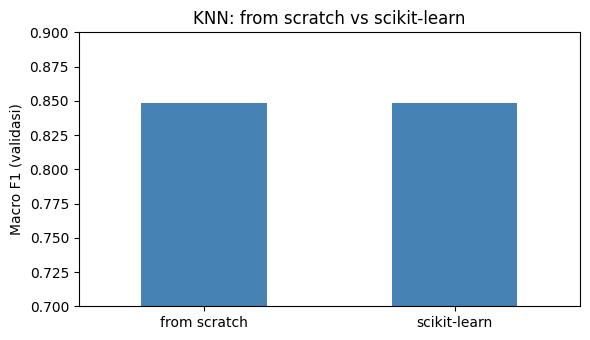

In [35]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score

sk_knn = KNeighborsClassifier(n_neighbors=BEST_K, p=BEST_P, weights=BEST_W, algorithm='brute')
sk_knn.fit(X_train, y_train)
sk_val_pred = sk_knn.predict(X_val)

comparison = pd.DataFrame({
    'from scratch': [macro_f1(y_val, knn_val_pred), accuracy(y_val, knn_val_pred)],
    'scikit-learn': [f1_score(y_val, sk_val_pred, average='macro'), np.mean(sk_val_pred == y_val)],
}, index=['macro F1', 'accuracy'])
print(comparison.round(4))
print(f'Prediksi identik: {np.mean(knn_val_pred == sk_val_pred):.2%}')

fig, ax = plt.subplots(figsize=(6, 3.5))
comparison.loc['macro F1'].plot.bar(ax=ax, color=CFG.PLOT_COLOR)
ax.set_ylim(0.7, 0.9)
ax.set_ylabel('Macro F1 (validasi)')
ax.set_title('KNN: from scratch vs scikit-learn')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Insights:**

Dengan *hyperparameter* dan data yang sama, prediksi KNN *from scratch* identik dengan `KNeighborsClassifier(algorithm='brute')`. Ini menunjukkan perhitungan jarak, pemilihan tetangga, dan voting berbobot sudah benar. Perbedaan utamanya ada pada kecepatan: scikit-learn memakai implementasi C yang lebih cepat.

### Perbandingan SVM

`SVC` menggunakan data, preprocessing, dan parameter kernel yang sama. Pada hasil validasi ini, prediksi linear dan polynomial identik dengan implementasi sendiri. Prediksi Gaussian berbeda pada satu booking.


            macro_f1_scratch  macro_f1_sklearn  accuracy_scratch  accuracy_sklearn  prediction_agreement  scratch_converged  sklearn_converged  sklearn_fit_seconds
kernel                                                                                                                                                             
linear                0.7599            0.7599            0.7978            0.7978                1.0000               True               True              19.6012
polynomial            0.7771            0.7771            0.8137            0.8137                1.0000               True               True               9.9841
gaussian              0.7933            0.7931            0.8267            0.8265                0.9998               True               True              12.5815


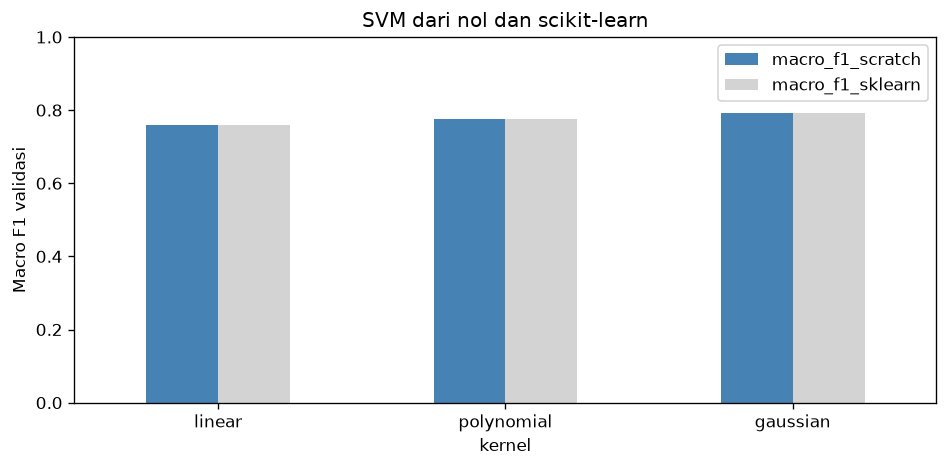

In [102]:
from sklearn.svm import SVC

sk_svm_models = {}
svm_comparison_rows = []
sklearn_kernels = {'linear': 'linear', 'polynomial': 'poly', 'gaussian': 'rbf'}
for kernel, scratch_model in svm_models.items():
    sk_model = SVC(C=scratch_model.C, kernel=sklearn_kernels[kernel],
                   degree=scratch_model.degree, gamma=scratch_model.gamma_,
                   coef0=scratch_model.coef0, tol=scratch_model.tol)
    start = time.time()
    sk_model.fit(X_svm_train, y_train)
    fit_seconds = time.time() - start
    sk_pred = sk_model.predict(X_svm_val)
    sk_svm_models[kernel] = sk_model
    svm_comparison_rows.append({
        'kernel': kernel,
        'macro_f1_scratch': macro_f1(y_val, svm_val_predictions[kernel]),
        'macro_f1_sklearn': f1_score(y_val, sk_pred, average='macro'),
        'accuracy_scratch': accuracy(y_val, svm_val_predictions[kernel]),
        'accuracy_sklearn': accuracy(y_val, sk_pred),
        'prediction_agreement': np.mean(svm_val_predictions[kernel] == sk_pred),
        'scratch_converged': bool(scratch_model.converged_),
        'sklearn_converged': sk_model.fit_status_ == 0,
        'sklearn_fit_seconds': fit_seconds,
    })

svm_comparison = pd.DataFrame(svm_comparison_rows).set_index('kernel')
print(svm_comparison.round(4).to_string())
ax = svm_comparison[['macro_f1_scratch', 'macro_f1_sklearn']].plot.bar(
    figsize=(8, 4), color=[CFG.PLOT_COLOR, 'lightgray'])
ax.set_ylabel('Macro F1 validasi')
ax.set_title('SVM dari nol dan scikit-learn')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [36]:
knn_path = CFG.MODEL_DIR / 'knn.pkl'
prep_path = CFG.MODEL_DIR / 'preprocessor.pkl'
knn.save(knn_path)
preprocessor.save(prep_path)

loaded_knn = KNN.load(knn_path)
loaded_prep = Preprocessor.load(prep_path)
reloaded_pred = loaded_knn.predict(loaded_prep.transform(val_set))
print('Prediksi model hasil load sama dengan model asli:', np.array_equal(reloaded_pred, knn_val_pred))

Prediksi model hasil load sama dengan model asli: True


### Menyimpan dan memuat SVM

Model setiap kernel dan preprocessor SVM disimpan di `output/models/`. Setelah dimuat kembali, ketiganya menghasilkan prediksi validasi yang sama dengan sebelum disimpan.


In [101]:
svm_prep_path = CFG.MODEL_DIR / 'svm_preprocessor.pkl'
svm_preprocessor.save(svm_prep_path)
loaded_svm_preprocessor = Preprocessor.load(svm_prep_path)
X_svm_val_loaded = loaded_svm_preprocessor.transform(val_set)

for kernel, model in svm_models.items():
    model_path = CFG.MODEL_DIR / f'svm_{kernel}.pkl'
    model.save(model_path)
    loaded_svm = SVM.load(model_path)
    loaded_pred = loaded_svm.predict(X_svm_val_loaded)
    assert np.array_equal(loaded_pred, svm_val_predictions[kernel])
    print(f'SVM {kernel}: prediksi sesudah save/load sama')


SVM linear: prediksi sesudah save/load sama
SVM polynomial: prediksi sesudah save/load sama
SVM gaussian: prediksi sesudah save/load sama


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [37]:
# Model akhir: preprocessor dan KNN di-fit ulang pada seluruh train.csv (tanpa duplikat).
full_train = drop_duplicate_rows(train_df)
final_prep = Preprocessor(scale=True, min_category_freq=20, add_derived=True, feature_weights=BEST_FW).fit(full_train)
final_knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W).fit(final_prep.transform(full_train), full_train[TARGET].to_numpy())

test_pred = final_knn.predict(final_prep.transform(test_df))   # Test hanya ditransformasi.
submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': test_pred.astype(int)})

assert len(submission) == len(test_df) and submission['id'].is_unique
assert set(submission['is_canceled'].unique()) <= {0, 1}
submission_path = CFG.OUTPUT_DIR / 'submission_knn.csv'
submission.to_csv(submission_path, index=False)
final_knn.save(CFG.MODEL_DIR / 'knn_final.pkl')
final_prep.save(CFG.MODEL_DIR / 'preprocessor_final.pkl')

print(submission_path, submission.shape)
print('Proporsi prediksi batal di test: %.3f' % submission['is_canceled'].mean())
submission.head()

d:\SEMESTER 5\2. AI\TUBES 2\IF3170_G25_IMKSIAI\output\submission_knn.csv (6844, 2)
Proporsi prediksi batal di test: 0.297


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


### Submission SVM

Gaussian dipilih karena Macro F1 validasinya paling tinggi, yaitu 0,7933. Model dan preprocessor dilatih ulang pada seluruh train setelah penghapusan duplikat. Test diproses dengan preprocessor tersebut, lalu prediksinya disimpan ke `submission_svm.csv`.


In [103]:
svm_final_preprocessor = Preprocessor(scale=True, min_category_freq=20,
                                      add_derived=True, feature_weights=None)
X_svm_full = svm_final_preprocessor.fit_transform(full_train)
X_svm_test = svm_final_preprocessor.transform(test_df)
svm_final = SVM(C=CFG.SVM_C, kernel=BEST_SVM_KERNEL, degree=CFG.SVM_DEGREE,
                tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_final.fit(X_svm_full, full_train[TARGET].to_numpy())
if not svm_final.converged_:
    raise RuntimeError('SVM final belum konvergen. Naikkan CFG.SVM_MAX_ITER sebelum membuat submission.')

svm_test_pred = svm_final.predict(X_svm_test)
svm_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': svm_test_pred.astype(int)})
sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
assert svm_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_submission['id'].equals(sample_submission['id'])
assert len(svm_submission) == len(test_df) and svm_submission['id'].is_unique
assert set(svm_submission['is_canceled'].unique()) <= {0, 1}

svm_submission_path = CFG.OUTPUT_DIR / 'submission_svm.csv'
svm_submission.to_csv(svm_submission_path, index=False)
svm_final.save(CFG.MODEL_DIR / 'svm_final.pkl')
svm_final_preprocessor.save(CFG.MODEL_DIR / 'svm_preprocessor_final.pkl')
print(svm_submission_path, svm_submission.shape)
print('Proporsi prediksi batal di test: %.3f' % svm_submission['is_canceled'].mean())
svm_submission.head()


C:\Projects\IF3170_G25_IMKSIAI\output\submission_svm.csv (6844, 2)
Proporsi prediksi batal di test: 0.269


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [38]:
cm = confusion_matrix(y_val, knn_val_pred)
print('Confusion matrix (baris = asli, kolom = prediksi):')
print(pd.DataFrame(cm, index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))
print('F1 per kelas:', f1_per_class(y_val, knn_val_pred).round(4))

err = val_set.assign(pred=knn_val_pred, wrong=knn_val_pred != y_val)
lead_bins = pd.cut(err['days_before_arrival'], [-1, 7, 30, 90, 180, 500])
print('\nTingkat kesalahan per lead time:')
print(err.groupby(lead_bins, observed=True)['wrong'].agg(['mean', 'size']).round(3))
print('\nTingkat kesalahan per kanal:')
print(err.groupby('booking_channel')['wrong'].agg(['mean', 'size']).round(3))

Confusion matrix (baris = asli, kolom = prediksi):
        pred 0  pred 1
asli 0    3374     307
asli 1     412    1382
F1 per kelas: [0.9037 0.7936]

Tingkat kesalahan per lead time:
                      mean  size
days_before_arrival             
(-1, 7]              0.069   802
(7, 30]              0.113   965
(30, 90]             0.158  1562
(90, 180]            0.181  1133
(180, 500]           0.063   767

Tingkat kesalahan per kanal:
                      mean  size
booking_channel                 
Airline              0.125    16
Complimentary        0.017    58
Corporate            0.068   309
Offline Agent        0.068  1573
Online Travel Agent  0.167  3519


**Insights:**

- F1 kelas tidak batal (sekitar 0,90) jauh lebih tinggi daripada kelas batal (sekitar 0,79). Kelas batal adalah titik lemah yang menurunkan Macro F1.
- Kesalahan paling banyak pada pesanan dengan lead time menengah (30–180 hari, tingkat salah 16–18%), di mana pola batal dan tidak batal paling bercampur. Lead time di bawah 7 hari atau di atas 180 hari jauh lebih mudah ditebak.
- Kanal *Online Travel Agent* memiliki tingkat salah tertinggi (sekitar 17%) dibanding *Offline Agent* atau *Corporate* (sekitar 7%).
- Perbaikan berikutnya: bandingkan dengan DTL (yang menangani interaksi fitur secara eksplisit) dan analisis *cost-sensitive* untuk bonus.

### Analisis kesalahan SVM

Confusion matrix menunjukkan jumlah prediksi benar dan salah. Baris menunjukkan label asli dan kolom menunjukkan prediksi. F1 per kelas digunakan untuk menilai hasil pada booking batal dan tidak batal.


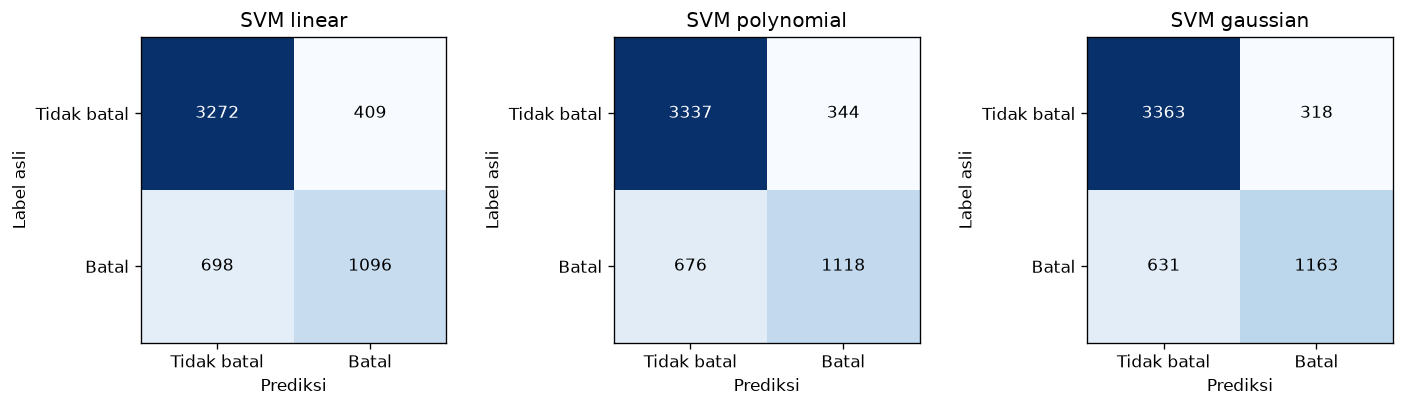

,kernel,f1_tidak_batal,f1_batal
0,linear,0.855313,0.664444
1,polynomial,0.867429,0.686732
2,gaussian,0.876352,0.710229


In [104]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
svm_class_rows = []
for ax, (kernel, pred) in zip(axes, svm_val_predictions.items()):
    svm_cm = confusion_matrix(y_val, pred)
    ax.imshow(svm_cm, cmap='Blues')
    for row in range(2):
        for column in range(2):
            color = 'white' if svm_cm[row, column] > svm_cm.max() / 2 else 'black'
            ax.text(column, row, str(svm_cm[row, column]), ha='center', va='center', color=color)
    ax.set_xticks([0, 1], ['Tidak batal', 'Batal'])
    ax.set_yticks([0, 1], ['Tidak batal', 'Batal'])
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Label asli')
    ax.set_title(f'SVM {kernel}')
    class_f1 = f1_per_class(y_val, pred)
    svm_class_rows.append({'kernel': kernel, 'f1_tidak_batal': class_f1[0], 'f1_batal': class_f1[1]})
plt.tight_layout()
plt.show()
pd.DataFrame(svm_class_rows)


---

# Cost-Sensitive Classification (Bonus) <a name="12"></a>

---

Tidak semua kesalahan prediksi sama mahalnya. Dengan kelas positif = batal (`is_canceled = 1`):

- **False Positive (FP)**: pesanan diprediksi batal padahal tamu datang. Kalau kamarnya sudah dijual lagi, penginapan menjadi *overbooked*.
- **False Negative (FN)**: pesanan diprediksi datang padahal batal. Akibatnya ada kamar kosong yang tidak terjual.

Sesuai spesifikasi, biaya FP dianggap **2 kali** biaya FN. Prediksi yang benar tidak menimbulkan biaya.

Model yang dipakai tetap KNN terbaik dari bagian Modeling. Yang berubah adalah **aturan keputusannya**. KNN memprediksi kelas dengan probabilitas terbesar, sehingga pesanan diprediksi batal jika $P(\text{batal}) > 0{,}5$. Aturan ini hanya optimal jika biaya FP dan FN sama.

Menurut aturan keputusan Bayes dengan biaya (Elkan, 2001), pesanan sebaiknya diprediksi batal hanya jika biaya harapannya lebih kecil daripada memprediksi datang:

$$(1 - p) \cdot C_{FP} < p \cdot C_{FN} \iff p > \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{2}{3}$$

dengan $p = P(\text{batal})$. Jadi model harus lebih yakin sebelum memprediksi batal.

Pada KNN, menaikkan ambang ke 2/3 sama dengan memberi bobot 2 pada suara tetangga kelas tidak batal saat voting.

Probabilitas KNN tidak terkalibrasi sempurna, jadi ambang 2/3 belum tentu yang terbaik untuk data ini. Karena itu ambang juga dicari langsung dengan meminimalkan biaya pada probabilitas *out-of-fold* data latih. Data validasi hanya dipakai untuk mengevaluasi.

In [39]:
# Matriks biaya: baris = label asli, kolom = prediksi.
COST_FP = 2.0   # Diprediksi batal padahal tamu datang, kamar bisa overbooked.
COST_FN = 1.0   # Diprediksi datang padahal batal, kamar kosong tidak terjual.
print(pd.DataFrame([[0, COST_FP], [COST_FN, 0]], index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))

# Ambang dari aturan keputusan Bayes dengan biaya (Elkan, 2001).
BAYES_THRESHOLD = COST_FP / (COST_FP + COST_FN)
print(f'\nAmbang teoretis: P(batal) > {BAYES_THRESHOLD:.3f}')

default_cost = misclassification_cost(y_val, knn_val_pred, COST_FP, COST_FN)
print(f'Biaya model default (ambang 0,5) di validasi: {default_cost:.0f}  ({default_cost / len(y_val):.4f} per pesanan)')

        pred 0  pred 1
asli 0     0.0     2.0
asli 1     1.0     0.0

Ambang teoretis: P(batal) > 0.667
Biaya model default (ambang 0,5) di validasi: 1026  (0.1874 per pesanan)


Ambang dengan biaya CV minimum   : 0.65
Ambang dengan Macro F1 CV maksimum: 0.50


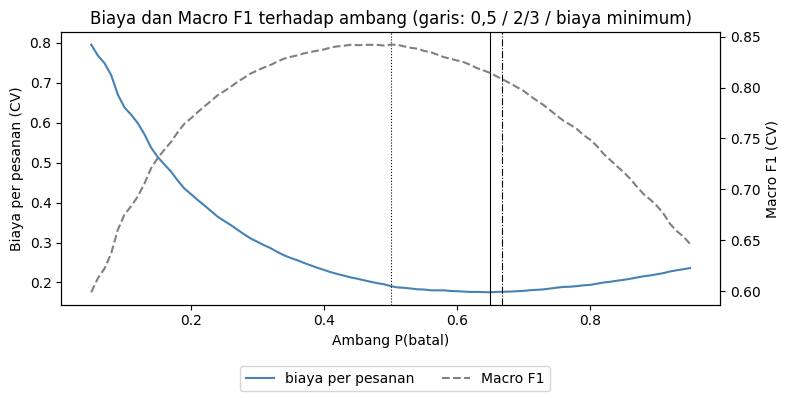

In [40]:
# Probabilitas out-of-fold pada data latih, supaya ambang tidak dipilih dari data validasi.
# Preprocessor di-fit ulang di setiap fold, sama seperti saat tuning hyperparameter.
oof_proba = np.zeros(len(train_set))
for tr_idx, va_idx in stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED):
    fold_tr, fold_va = train_set.iloc[tr_idx], train_set.iloc[va_idx]
    pp = Preprocessor(feature_weights=BEST_FW).fit(fold_tr)
    fold_knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W).fit(pp.transform(fold_tr), y_train[tr_idx])
    oof_proba[va_idx] = fold_knn.predict_proba(pp.transform(fold_va))[:, 1]

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep_rows = []
for t in thresholds:
    pred = (oof_proba > t).astype(int)
    sweep_rows.append({
        'threshold': t,
        'cost_per_booking': misclassification_cost(y_train, pred, COST_FP, COST_FN) / len(y_train),
        'macro_f1': macro_f1(y_train, pred),
    })
sweep = pd.DataFrame(sweep_rows)

CV_THRESHOLD = float(sweep.loc[sweep['cost_per_booking'].idxmin(), 'threshold'])
F1_THRESHOLD = float(sweep.loc[sweep['macro_f1'].idxmax(), 'threshold'])
print(f'Ambang dengan biaya CV minimum   : {CV_THRESHOLD:.2f}')
print(f'Ambang dengan Macro F1 CV maksimum: {F1_THRESHOLD:.2f}')

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sweep['threshold'], sweep['cost_per_booking'], color=CFG.PLOT_COLOR, label='biaya per pesanan')
ax1.set_xlabel('Ambang P(batal)')
ax1.set_ylabel('Biaya per pesanan (CV)')
ax2 = ax1.twinx()
ax2.plot(sweep['threshold'], sweep['macro_f1'], color='gray', linestyle='--', label='Macro F1')
ax2.set_ylabel('Macro F1 (CV)')
for t, style in [(0.5, ':'), (BAYES_THRESHOLD, '-.'), (CV_THRESHOLD, '-')]:
    ax1.axvline(t, color='black', linestyle=style, linewidth=0.8)
ax1.set_title('Biaya dan Macro F1 terhadap ambang (garis: 0,5 / 2/3 / biaya minimum)')
fig.legend(loc='lower center', ncol=2)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

                  ambang    TN   FP   FN    TP  total_biaya  biaya_per_pesanan  precision_batal  recall_batal  macro_f1
aturan                                                                                                                 
default            0.500  3374  307  412  1382       1026.0             0.1874           0.8182        0.7703    0.8486
Bayes 2/3          0.667  3557  124  675  1119        923.0             0.1686           0.9002        0.6237    0.8180
biaya minimum CV   0.650  3542  139  644  1150        922.0             0.1684           0.8922        0.6410    0.8232

Penurunan biaya dibanding ambang default: 10.1%


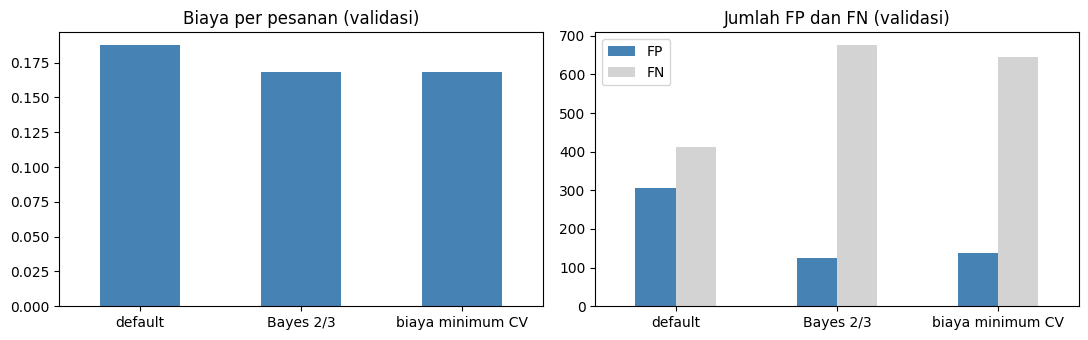

In [41]:
# Evaluasi ketiga ambang di data validasi dengan model KNN yang sama.
val_proba = knn.predict_proba(X_val)[:, 1]
# Ambang 0,5 harus memberi prediksi yang sama dengan knn.predict.
assert np.array_equal((val_proba > 0.5).astype(int), knn_val_pred)

cost_rows = []
for name, t in [('default', 0.5), ('Bayes 2/3', BAYES_THRESHOLD), ('biaya minimum CV', CV_THRESHOLD)]:
    pred = (val_proba > t).astype(int)
    (tn, fp), (fn, tp) = confusion_matrix(y_val, pred)
    total = misclassification_cost(y_val, pred, COST_FP, COST_FN)
    cost_rows.append({
        'aturan': name, 'ambang': round(t, 3), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'total_biaya': total,
        'biaya_per_pesanan': total / len(y_val),
        'precision_batal': tp / (tp + fp) if tp + fp > 0 else 0.0,
        'recall_batal': tp / (tp + fn) if tp + fn > 0 else 0.0,
        'macro_f1': macro_f1(y_val, pred),
    })
cost_table = pd.DataFrame(cost_rows).set_index('aturan')
print(cost_table.round(4).to_string())

saving = 1 - cost_table.loc['biaya minimum CV', 'total_biaya'] / cost_table.loc['default', 'total_biaya']
print(f'\nPenurunan biaya dibanding ambang default: {saving:.1%}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
cost_table['biaya_per_pesanan'].plot.bar(ax=axes[0], color=CFG.PLOT_COLOR)
axes[0].set_title('Biaya per pesanan (validasi)')
cost_table[['FP', 'FN']].plot.bar(ax=axes[1], color=[CFG.PLOT_COLOR, 'lightgray'])
axes[1].set_title('Jumlah FP dan FN (validasi)')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Insights:**

- **Biaya turun 10,1%.** Dengan ambang default 0,5, total biaya di validasi adalah 1.026 (0,187 per pesanan). Ambang biaya minimum hasil CV (0,65) menurunkannya menjadi 922 (0,168 per pesanan).
- **FP turun lebih dari setengah.** Jumlah FP turun dari 307 menjadi 139, sedangkan FN naik dari 412 menjadi 644. Pengurangan 168 FP menghemat 336, sementara tambahan 232 FN hanya menambah 232, sehingga biaya bersih turun 104.
- **Ambang hasil CV (0,65) hampir sama dengan ambang teoretis 2/3 (0,667).** Biaya keduanya di validasi juga hampir sama (922 dan 923). Artinya probabilitas dari KNN berbobot jarak sudah cukup terkalibrasi, sehingga aturan keputusan Bayes langsung bisa dipakai.
- **Precision kelas batal naik dari 0,818 menjadi 0,892, recall turun dari 0,770 menjadi 0,641.** Pesanan yang diprediksi batal kini lebih bisa dipercaya untuk dijual ulang tanpa risiko *overbooking*, dengan konsekuensi lebih banyak pembatalan yang tidak terdeteksi.
- **Macro F1 turun dari 0,849 menjadi 0,823.** Pada CV, Macro F1 justru maksimum di ambang 0,50. Jadi ambang default memang terbaik untuk metrik Kaggle, sedangkan ambang 0,65 terbaik untuk biaya. Metrik evaluasi harus mengikuti tujuan bisnisnya.

**Perubahan penanganan pada task ini:**

1. **Metrik pemilihan model** berubah dari Macro F1 menjadi total biaya ($2 \cdot FP + 1 \cdot FN$).
2. **Aturan keputusan** berubah dari ambang 0,5 menjadi ambang yang meminimalkan biaya, dipilih dengan *cross-validation* di data latih.
3. **Modelnya tidak berubah.** Pendekatan ini tidak memerlukan pelatihan ulang dan tetap satu model KNN, sehingga tidak termasuk *ensemble*.
4. **Submisi Kaggle tetap memakai ambang default**, karena leaderboard dinilai dengan Macro F1. Bagian ini adalah analisis tambahan dan tidak mengubah `output/submission_knn.csv`.

Referensi: C. Elkan, "The Foundations of Cost-Sensitive Learning," *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI)*, 2001, pp. 973–978.

---

# Visualisasi SVM 2D (Bonus) <a name="13"></a>

Gambar menggunakan dua fitur, yaitu jarak pemesanan ke kedatangan dan harga per malam. Kedua fitur diambil dari hasil preprocessing data latih. Sampel 600 booking dipilih dengan seed tetap, lalu setiap kernel dilatih ulang pada dua fitur tersebut khusus untuk visualisasi.

Garis penuh menunjukkan batas keputusan f(x)=0. Garis putus-putus menunjukkan margin f(x)=-1 dan f(x)=1. Lingkaran menandai support vector. Pada soft margin, sebagian support vector dapat berada di dalam margin atau di sisi yang salah. Kedua sumbu memakai z-score sesuai preprocessing.


In [105]:
svm_2d_features = ['days_before_arrival', 'nightly_rate_idr']
svm_2d_columns = [svm_preprocessor.feature_names_.index(name) for name in svm_2d_features]
svm_2d_indices = np.random.default_rng(CFG.SEED).choice(
    len(X_svm_train), size=min(600, len(X_svm_train)), replace=False)
X_svm_2d = X_svm_train[svm_2d_indices][:, svm_2d_columns]
y_svm_2d = y_train[svm_2d_indices]
assert X_svm_2d.shape[1] == 2 and np.isfinite(X_svm_2d).all()

svm_2d_models = {}
svm_2d_rows = []
for kernel in SVM.VALID_KERNELS:
    model_2d = SVM(C=CFG.SVM_C, kernel=kernel, degree=CFG.SVM_DEGREE,
                   tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
    model_2d.fit(X_svm_2d, y_svm_2d)
    if not model_2d.converged_:
        raise RuntimeError(f'SVM 2D {kernel} belum konvergen. Naikkan CFG.SVM_MAX_ITER.')
    svm_2d_models[kernel] = model_2d
    svm_2d_rows.append({
        'kernel': kernel,
        'jumlah_data': len(X_svm_2d),
        'support_vector': len(model_2d.support_),
        'iterasi': model_2d.n_iter_,
        'konvergen': bool(model_2d.converged_),
    })
pd.DataFrame(svm_2d_rows)


,kernel,jumlah_data,support_vector,iterasi,konvergen
0,linear,600,362,1518,True
1,polynomial,600,350,6301,True
2,gaussian,600,348,1107,True


Gambar disimpan: C:\Projects\IF3170_G25_IMKSIAI\output\visualization\svm\svm_linear.png
Gambar disimpan: C:\Projects\IF3170_G25_IMKSIAI\output\visualization\svm\svm_polynomial.png
Gambar disimpan: C:\Projects\IF3170_G25_IMKSIAI\output\visualization\svm\svm_gaussian.png


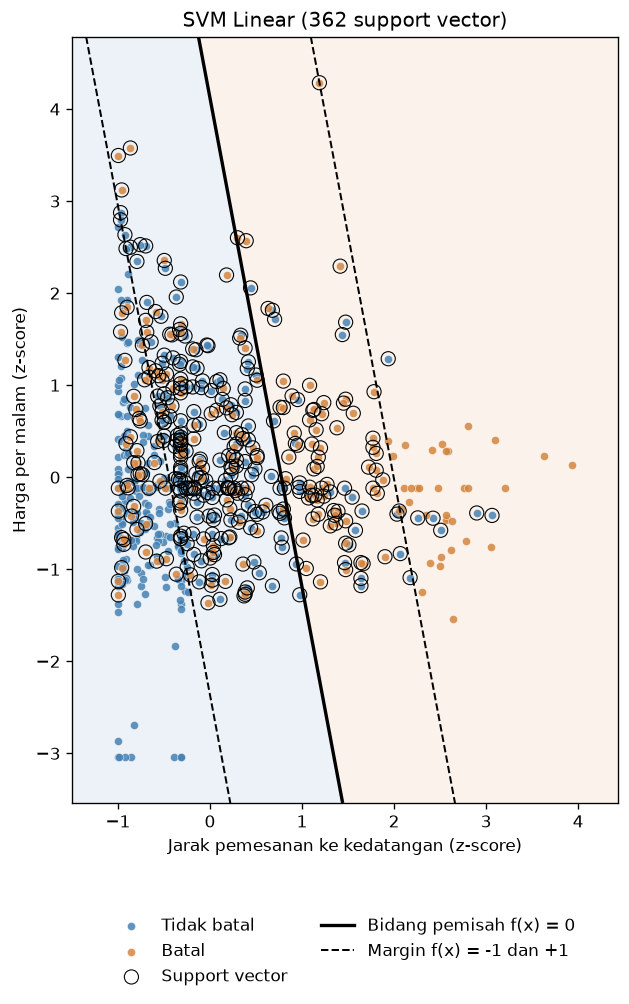

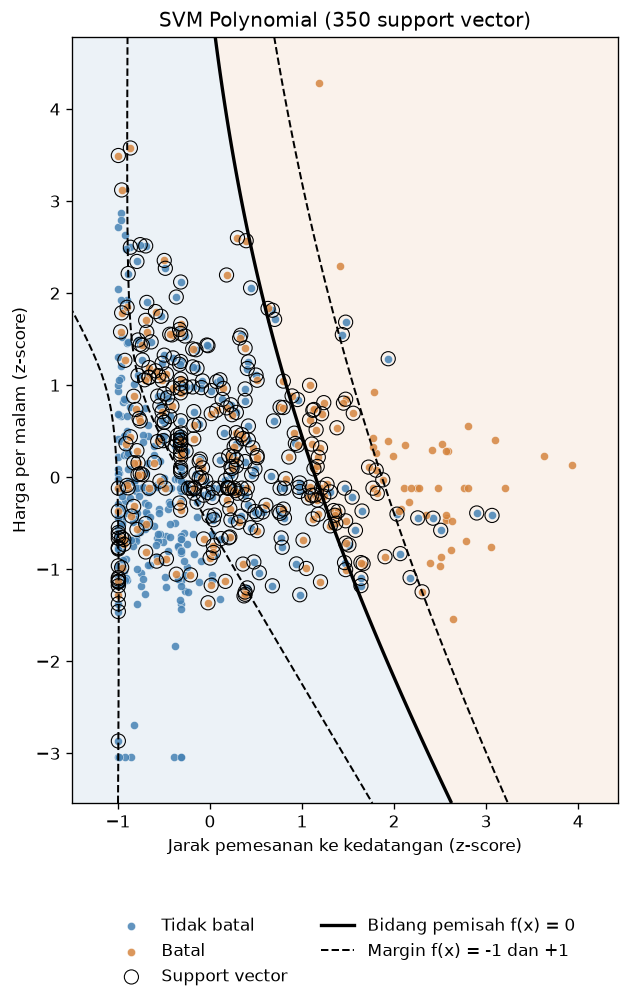

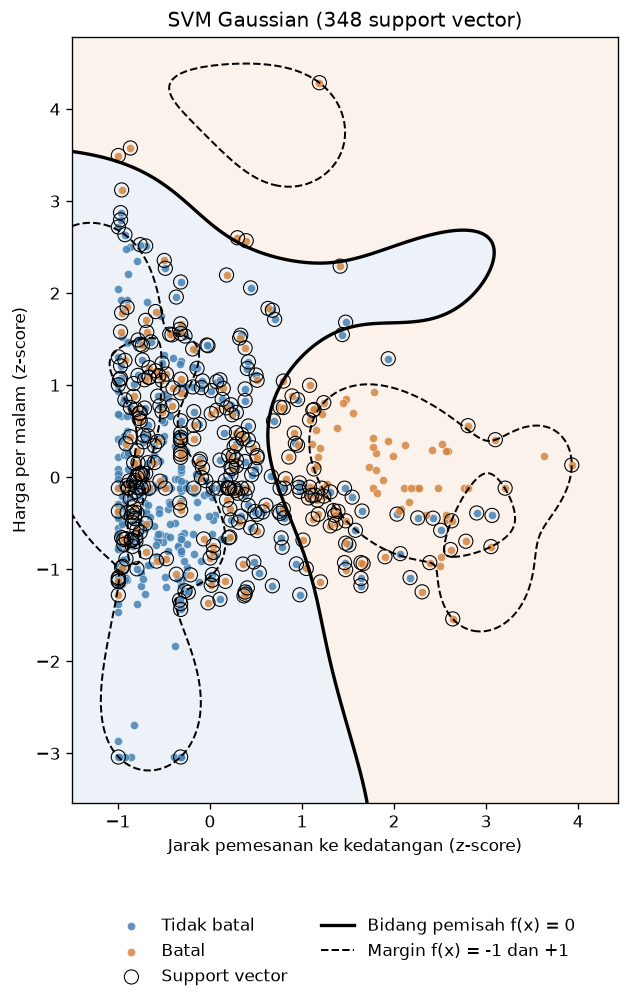

In [106]:
svm_visualization_dir = CFG.OUTPUT_DIR / 'visualization' / 'svm'
svm_visualization_dir.mkdir(parents=True, exist_ok=True)

svm_2d_min = X_svm_2d.min(axis=0) - 0.5
svm_2d_max = X_svm_2d.max(axis=0) + 0.5
svm_2d_x, svm_2d_y = np.meshgrid(
    np.linspace(svm_2d_min[0], svm_2d_max[0], 250),
    np.linspace(svm_2d_min[1], svm_2d_max[1], 250))
svm_2d_grid = np.column_stack([svm_2d_x.ravel(), svm_2d_y.ravel()])
svm_2d_colors = [CFG.PLOT_COLOR, '#d5853f']
svm_2d_names = {'linear': 'Linear', 'polynomial': 'Polynomial', 'gaussian': 'Gaussian'}

for kernel, model_2d in svm_2d_models.items():
    scores_2d = model_2d.decision_function(svm_2d_grid).reshape(svm_2d_x.shape)
    assert np.isfinite(scores_2d).all()
    assert scores_2d.min() < -1 and scores_2d.max() > 1, 'Rentang gambar belum mencakup kedua margin.'
    fig, ax = plt.subplots(figsize=(8, 8.5))
    ax.contourf(svm_2d_x, svm_2d_y, scores_2d,
                levels=[scores_2d.min() - 1, 0, scores_2d.max() + 1],
                colors=svm_2d_colors, alpha=0.10)
    for label, name, color in [(0, 'Tidak batal', svm_2d_colors[0]),
                                (1, 'Batal', svm_2d_colors[1])]:
        points = X_svm_2d[y_svm_2d == label]
        ax.scatter(points[:, 0], points[:, 1], s=24, color=color,
                   edgecolors='white', linewidths=0.3, alpha=0.85, label=name, zorder=2)
    support_2d = X_svm_2d[model_2d.support_]
    ax.scatter(support_2d[:, 0], support_2d[:, 1], s=72, facecolors='none',
               edgecolors='black', linewidths=0.65, label='Support vector', zorder=3)
    boundaries_2d = ax.contour(
        svm_2d_x, svm_2d_y, scores_2d, levels=[-1, 0, 1], colors='black',
        linestyles=['--', '-', '--'], linewidths=[1.2, 2, 1.2])
    assert all(any(len(segment) > 1 for segment in level) for level in boundaries_2d.allsegs)
    ax.plot([], [], color='black', linewidth=2, label='Bidang pemisah f(x) = 0')
    ax.plot([], [], color='black', linestyle='--', linewidth=1.2, label='Margin f(x) = -1 dan +1')
    ax.set_xlim(svm_2d_min[0], svm_2d_max[0])
    ax.set_ylim(svm_2d_min[1], svm_2d_max[1])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Jarak pemesanan ke kedatangan (z-score)')
    ax.set_ylabel('Harga per malam (z-score)')
    ax.set_title(f'SVM {svm_2d_names[kernel]} ({len(model_2d.support_)} support vector)')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
    fig.tight_layout()
    image_path_2d = svm_visualization_dir / f'svm_{kernel}.png'
    fig.savefig(image_path_2d, dpi=240, bbox_inches='tight')
    print('Gambar disimpan:', image_path_2d)
    plt.show()


**Pembahasan:**

Kernel linear menghasilkan batas berupa garis lurus. Polynomial dan Gaussian dapat menghasilkan batas melengkung. Titik dari kedua kelas masih saling bercampur pada dua fitur ini.


---

# Optimasi SVM dengan Differential Evolution (Bonus) <a name="14"></a>

Optimasi difokuskan pada kernel Gaussian yang memperoleh Macro F1 tertinggi pada percobaan awal. Parameter yang dicari adalah C untuk penalti pelanggaran margin, gamma untuk jangkauan pengaruh titik, serta ambang keputusan untuk menentukan prediksi booking batal.

[Differential Evolution, Storn dan Price (1997)](https://doi.org/10.1023/A:1008202821328) diimplementasikan dengan NumPy pada `svm.py`. Algoritma membentuk kandidat melalui mutasi dan crossover, lalu mempertahankan kandidat dengan Macro F1 CV lebih tinggi tanpa memerlukan gradien. Pencarian C dan gamma pada skala log mengacu pada [panduan Hsu, Chang, dan Lin](https://www.csie.ntu.edu.tw/~cjlin/papers/guide/guide.pdf). Pemilihan ambang mengacu pada [Lipton dkk. (2014)](https://arxiv.org/abs/1402.1892), dengan Macro F1 dihitung langsung melalui CV. Skor SVM tidak dianggap sebagai probabilitas.

Pencarian memakai 4.000 data training, tiga fold, delapan kandidat, dan empat generasi. Dua kandidat terbaik dan model awal diperiksa kembali pada 8.000 data training. Preprocessing hanya dilatih pada bagian latih setiap fold. Parameter dipilih dari CV, lalu ambang nol dan ambang hasil CV dibandingkan pada split validasi lama. Data test hanya digunakan untuk menghasilkan prediksi.


In [107]:
import warnings

svm_de_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 4000 / len(train_set)), random_state=CFG.SEED).reset_index(drop=True)

def prepare_svm_cv(data):
    labels = data[TARGET].to_numpy()
    folds = []
    for train_indices, val_indices in stratified_kfold_indices(labels, 3, CFG.SEED):
        fold_train = data.iloc[train_indices]
        fold_val = data.iloc[val_indices]
        prep = Preprocessor(feature_weights=None).fit(fold_train)
        folds.append((prep.transform(fold_train), labels[train_indices],
                      prep.transform(fold_val), labels[val_indices]))
    return folds

def score_svm_candidate(point, folds, tolerance, max_iter):
    C, gamma, threshold = 10 ** point[0], 10 ** point[1], float(point[2])
    scores = []
    for X_fold_train, y_fold_train, X_fold_val, y_fold_val in folds:
        model = SVM(C=C, kernel='gaussian', gamma=gamma, decision_threshold=threshold,
                    tol=tolerance, max_iter=max_iter)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)
            model.fit(X_fold_train, y_fold_train)
        if not model.converged_:
            return 0.0, 0.0, False
        scores.append(macro_f1(y_fold_val, model.predict(X_fold_val)))
    return float(np.mean(scores)), float(np.std(scores)), True

svm_de_folds = prepare_svm_cv(svm_de_data)
svm_de_history = []
def svm_de_objective(point):
    start = time.time()
    score, deviation, converged = score_svm_candidate(point, svm_de_folds, 0.01, 100000)
    svm_de_history.append({
        'evaluation': len(svm_de_history) + 1,
        'C': float(10 ** point[0]), 'gamma': float(10 ** point[1]),
        'decision_threshold': float(point[2]),
        'cv_macro_f1': score, 'cv_std': deviation,
        'converged': converged, 'seconds': time.time() - start,
    })
    print(f'Evaluasi {len(svm_de_history)}: CV Macro F1 = {score:.4f}, '
          f'konvergen = {converged}', flush=True)
    return score

svm_de_initial = np.array([np.log10(svm_models['gaussian'].C),
                           np.log10(svm_models['gaussian'].gamma_), 0.0])
print('Jumlah data pencarian:', len(svm_de_data))


Jumlah data pencarian: 4000


In [108]:
svm_de_bounds = [(-1, 2), (-3, 0), (-0.5, 0.2)]
svm_de_point, svm_de_score = differential_evolution(
    svm_de_objective, svm_de_bounds, svm_de_initial,
    population_size=8, generations=4, seed=CFG.SEED)
svm_de_trials = pd.DataFrame(svm_de_history)
assert len(svm_de_trials) == 40
assert svm_de_score >= svm_de_trials.iloc[0]['cv_macro_f1']
assert np.all(svm_de_point >= np.array(svm_de_bounds)[:, 0])
assert np.all(svm_de_point <= np.array(svm_de_bounds)[:, 1])
svm_de_trials.to_csv(CFG.OUTPUT_DIR / 'svm_optimization_history.csv', index=False)
svm_de_trials.sort_values('cv_macro_f1', ascending=False).head(5)


Evaluasi 1: CV Macro F1 = 0.7665, konvergen = True
Evaluasi 2: CV Macro F1 = 0.7344, konvergen = True
Evaluasi 3: CV Macro F1 = 0.7493, konvergen = True
Evaluasi 4: CV Macro F1 = 0.7492, konvergen = True
Evaluasi 5: CV Macro F1 = 0.7650, konvergen = True
Evaluasi 6: CV Macro F1 = 0.7617, konvergen = True
Evaluasi 7: CV Macro F1 = 0.7737, konvergen = True
Evaluasi 8: CV Macro F1 = 0.6992, konvergen = True
Evaluasi 9: CV Macro F1 = 0.7672, konvergen = True
Evaluasi 10: CV Macro F1 = 0.7500, konvergen = True
Evaluasi 11: CV Macro F1 = 0.7612, konvergen = True
Evaluasi 12: CV Macro F1 = 0.7618, konvergen = True
Evaluasi 13: CV Macro F1 = 0.6798, konvergen = True
Evaluasi 14: CV Macro F1 = 0.5857, konvergen = True
Evaluasi 15: CV Macro F1 = 0.7541, konvergen = True
Evaluasi 16: CV Macro F1 = 0.7651, konvergen = True
Generasi 1: skor terbaik = 0.7737
Evaluasi 17: CV Macro F1 = 0.7486, konvergen = True
Evaluasi 18: CV Macro F1 = 0.7783, konvergen = True
Evaluasi 19: CV Macro F1 = 0.6955, konv

,evaluation,C,gamma,decision_threshold,cv_macro_f1,cv_std,converged,seconds
34,35,3.235436,0.060966,-0.239957,0.789256,0.012686,True,2.847045
35,36,16.020070,0.060839,-0.075471,0.784192,0.013740,True,8.046558
26,27,0.851856,0.156494,-0.500000,0.782535,0.007992,True,1.913521
20,21,0.448570,0.293958,-0.500000,0.781384,0.002370,True,1.922025
17,18,7.905276,0.117114,-0.161727,0.778272,0.011485,True,5.562606


In [109]:
svm_de_shortlist = svm_de_trials[svm_de_trials['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').drop_duplicates(
        ['C', 'gamma', 'decision_threshold']).head(2)
svm_de_shortlist = pd.concat([svm_de_trials.iloc[[0]], svm_de_shortlist], ignore_index=True)
svm_de_shortlist = svm_de_shortlist.drop_duplicates(['C', 'gamma', 'decision_threshold'])
svm_de_confirmation_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 8000 / len(train_set)), random_state=CFG.SEED + 1).reset_index(drop=True)
svm_de_confirmation_folds = prepare_svm_cv(svm_de_confirmation_data)
svm_de_confirmation_rows = []
for row in svm_de_shortlist.to_dict('records'):
    point = np.array([np.log10(row['C']), np.log10(row['gamma']), row['decision_threshold']])
    score, deviation, converged = score_svm_candidate(
        point, svm_de_confirmation_folds, CFG.SVM_TOL, CFG.SVM_MAX_ITER)
    svm_de_confirmation_rows.append({
        'C': row['C'], 'gamma': row['gamma'], 'decision_threshold': row['decision_threshold'],
        'cv_macro_f1': score, 'cv_std': deviation, 'converged': converged,
    })
    print(f'Konfirmasi C={row["C"]:.4f}, gamma={row["gamma"]:.5f}, '
          f'ambang={row["decision_threshold"]:.4f}: CV Macro F1 = {score:.4f}', flush=True)
svm_de_confirmation = pd.DataFrame(svm_de_confirmation_rows)
svm_de_confirmation.to_csv(CFG.OUTPUT_DIR / 'svm_optimization_cv.csv', index=False)
svm_de_valid_candidates = svm_de_confirmation[svm_de_confirmation['converged']]
if svm_de_valid_candidates.empty:
    raise RuntimeError('Tidak ada kandidat optimasi yang konvergen pada CV konfirmasi.')
svm_de_best = svm_de_valid_candidates.sort_values('cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_de_confirmation


Konfirmasi C=1.0000, gamma=0.02857, ambang=0.0000: CV Macro F1 = 0.7738
Konfirmasi C=3.2354, gamma=0.06097, ambang=-0.2400: CV Macro F1 = 0.7983
Konfirmasi C=16.0201, gamma=0.06084, ambang=-0.0755: CV Macro F1 = 0.8021


,C,gamma,decision_threshold,cv_macro_f1,cv_std,converged
0,1.000000,0.028571,0.000000,0.773814,0.007933,True
1,3.235436,0.060966,-0.239957,0.798253,0.006814,True
2,16.020070,0.060839,-0.075471,0.802099,0.003727,True


### Evaluasi hasil optimasi

C, gamma, dan kandidat ambang dipilih melalui CV konfirmasi. Model kemudian dilatih pada seluruh training split. Ambang nol dan ambang hasil CV dibandingkan pada validasi untuk memilih aturan submission. Pembanding `SVC` memakai C, gamma, serta aturan keputusan yang sama. Karena validasi dipakai untuk memilih aturan akhir, skornya merupakan hasil pemilihan model lokal.


In [110]:
svm_de_cv_threshold = float(svm_de_best['decision_threshold'])
svm_optimized = SVM(C=float(svm_de_best['C']), kernel='gaussian',
                    gamma=float(svm_de_best['gamma']), decision_threshold=svm_de_cv_threshold,
                    tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_optimized.fit(X_svm_train, y_train)
if not svm_optimized.converged_:
    raise RuntimeError('SVM hasil optimasi belum konvergen pada training split.')
svm_optimized_scores = svm_optimized.decision_function(X_svm_val)
svm_de_zero_pred = (svm_optimized_scores >= 0).astype(int)
svm_de_cv_pred = (svm_optimized_scores >= svm_de_cv_threshold).astype(int)
if macro_f1(y_val, svm_de_zero_pred) >= macro_f1(y_val, svm_de_cv_pred):
    svm_de_submission_threshold = 0.0
else:
    svm_de_submission_threshold = svm_de_cv_threshold
svm_optimized.decision_threshold = svm_de_submission_threshold
svm_optimized_pred = svm_optimized.predict(X_svm_val)
sk_svm_optimized = SVC(C=svm_optimized.C, kernel='rbf', gamma=svm_optimized.gamma_,
                       tol=svm_optimized.tol)
sk_svm_optimized.fit(X_svm_train, y_train)
sk_svm_optimized_pred = (sk_svm_optimized.decision_function(X_svm_val)
                         >= svm_de_submission_threshold).astype(int)
svm_de_evaluation = pd.DataFrame([
    {'model': 'Gaussian awal', 'macro_f1': macro_f1(y_val, svm_val_predictions['gaussian']),
     'accuracy': accuracy(y_val, svm_val_predictions['gaussian'])},
    {'model': 'DE, ambang 0', 'macro_f1': macro_f1(y_val, svm_de_zero_pred),
     'accuracy': accuracy(y_val, svm_de_zero_pred)},
    {'model': 'DE, ambang CV', 'macro_f1': macro_f1(y_val, svm_de_cv_pred),
     'accuracy': accuracy(y_val, svm_de_cv_pred)},
    {'model': 'SVC, ambang terpilih', 'macro_f1': macro_f1(y_val, sk_svm_optimized_pred),
     'accuracy': accuracy(y_val, sk_svm_optimized_pred)},
])
svm_de_gain = macro_f1(y_val, svm_optimized_pred) - macro_f1(y_val, svm_val_predictions['gaussian'])
print(f'Ambang untuk submission: {svm_de_submission_threshold:.4f}')
print(f'Perubahan Macro F1 validasi: {svm_de_gain:+.4f}')
print(f'Kesamaan prediksi dengan SVC: {np.mean(svm_optimized_pred == sk_svm_optimized_pred):.2%}')
svm_optimized.save(CFG.MODEL_DIR / 'svm_optimized.pkl')
svm_preprocessor.save(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
loaded_svm_optimized = SVM.load(CFG.MODEL_DIR / 'svm_optimized.pkl')
loaded_svm_optimized_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
assert np.array_equal(loaded_svm_optimized.predict(loaded_svm_optimized_prep.transform(val_set)),
                      svm_optimized_pred)
svm_de_evaluation


Ambang untuk submission: 0.0000
Perubahan Macro F1 validasi: +0.0309
Kesamaan prediksi dengan SVC: 99.98%


,model,macro_f1,accuracy
0,Gaussian awal,0.793290,0.826667
1,"DE, ambang 0",0.824211,0.848402
2,"DE, ambang CV",0.821070,0.844566
3,"SVC, ambang terpilih",0.824396,0.848584


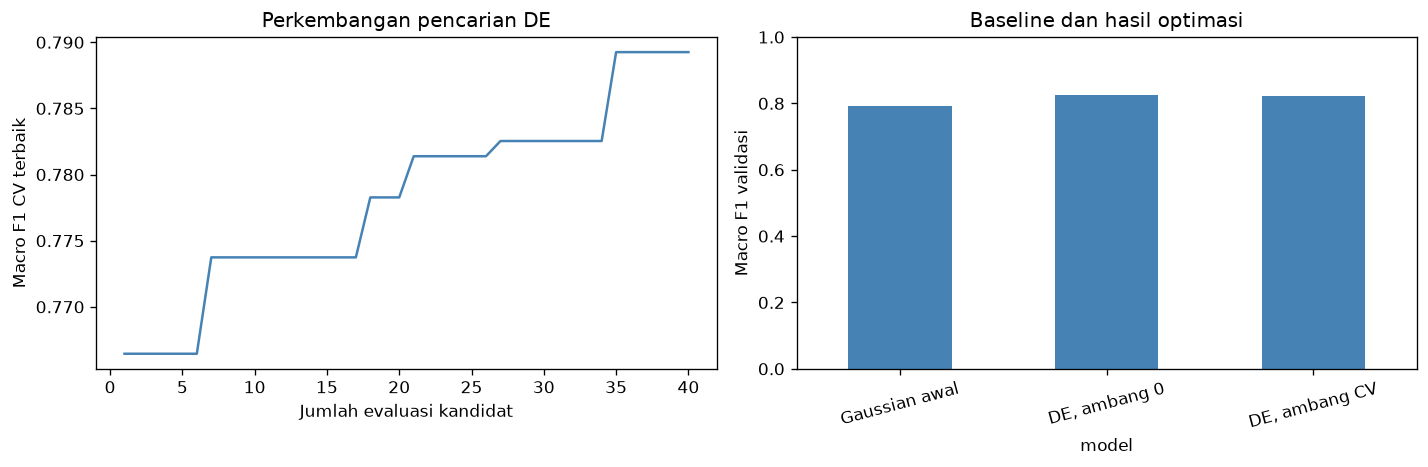

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(svm_de_trials['evaluation'], svm_de_trials['cv_macro_f1'].cummax(), color=CFG.PLOT_COLOR)
axes[0].set_xlabel('Jumlah evaluasi kandidat')
axes[0].set_ylabel('Macro F1 CV terbaik')
axes[0].set_title('Perkembangan pencarian DE')
svm_de_evaluation.iloc[:3].plot.bar(x='model', y='macro_f1', ax=axes[1],
                                  color=CFG.PLOT_COLOR, legend=False)
axes[1].set_ylabel('Macro F1 validasi')
axes[1].set_title('Baseline dan hasil optimasi')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()


In [112]:
svm_optimized_final_preprocessor = Preprocessor(feature_weights=None).fit(full_train)
svm_optimized_final = SVM(C=svm_optimized.C, kernel='gaussian', gamma=svm_optimized.gamma,
                          decision_threshold=svm_optimized.decision_threshold,
                          tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_optimized_final.fit(svm_optimized_final_preprocessor.transform(full_train),
                        full_train[TARGET].to_numpy())
if not svm_optimized_final.converged_:
    raise RuntimeError('SVM final hasil optimasi belum konvergen.')
svm_optimized_test_pred = svm_optimized_final.predict(svm_optimized_final_preprocessor.transform(test_df))
svm_optimized_submission = pd.DataFrame({'id': test_df['id'],
                                        'is_canceled': svm_optimized_test_pred.astype(int)})
assert svm_optimized_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_optimized_submission['id'].equals(sample_submission['id'])
assert len(svm_optimized_submission) == len(test_df) and svm_optimized_submission['id'].is_unique
assert set(svm_optimized_submission['is_canceled'].unique()) <= {0, 1}
svm_optimized_submission_path = CFG.OUTPUT_DIR / 'submission_svm_optimized.csv'
svm_optimized_submission.to_csv(svm_optimized_submission_path, index=False)
svm_optimized_final.save(CFG.MODEL_DIR / 'svm_optimized_final.pkl')
svm_optimized_final_preprocessor.save(CFG.MODEL_DIR / 'svm_optimized_preprocessor_final.pkl')
print(svm_optimized_submission_path, svm_optimized_submission.shape)
svm_optimized_submission.head()


C:\Projects\IF3170_G25_IMKSIAI\output\submission_svm_optimized.csv (6844, 2)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


**Pembahasan:**

Pencarian awal menaikkan Macro F1 CV dari 0,7665 menjadi 0,7893. Pada CV konfirmasi, baseline memperoleh 0,7738 dan kandidat terpilih memperoleh 0,8021. Parameter yang terpilih adalah C sekitar 16,02 dan gamma sekitar 0,06084.

Pada validasi, parameter DE dengan ambang nol memperoleh Macro F1 0,8242, dibandingkan baseline 0,7933. Ambang hasil CV sebesar -0,07547 memperoleh 0,8211. Ambang nol dipakai untuk submission karena menghasilkan skor validasi yang lebih tinggi. Percobaan ini menunjukkan bahwa perubahan ambang tidak selalu membantu pada data lain.


---

# Optimasi Lanjutan SVM (Bonus) <a name="15"></a>

Optimasi ini menguji representasi fitur, pembobotan fitur dan kelas, serta parameter C dan gamma.Differential Evolution mencari kombinasi parameter melalui mutasi, crossover, dan seleksi berdasarkan Macro F1 CV. Sebanyak 32 kandidat dievaluasi menggunakan tiga fold pada 8.000 data training. Preprocessing hanya dilatih pada bagian latih setiap fold.

Kandidat terbaik diperhalus melalui pencarian lokal, lalu dibandingkan dengan model sebelumnya menggunakan CV pada seluruh training split. Model dipilih berdasarkan Macro F1 CV dengan ambang keputusan nol. Validasi lama digunakan untuk pelaporan hasil sehingga belum menjadi evaluasi independen.

In [137]:
svm_refine_feature_options = {
    'Awal': None,
    'Log riwayat': dict(log_history=True, binary_unscaled=False, date_encoding='original'),
    'Biner 0/1': dict(log_history=False, binary_unscaled=True, date_encoding='original'),
    'Log dan biner': dict(log_history=True, binary_unscaled=True, date_encoding='original'),
    'Tanggal ordinal': dict(log_history=True, binary_unscaled=True, date_encoding='ordinal'),
    'Tanggal siklik': dict(log_history=True, binary_unscaled=True, date_encoding='cyclical'),
}
svm_refine_base_parameters = {'C': float(svm_optimized.C), 'gamma': float(svm_optimized.gamma_)}

def make_svm_refine_preprocessor(features):
    if features == 'Bobot fitur':
        return Preprocessor(feature_weights=CFG.FEATURE_WEIGHTS)
    options = svm_refine_feature_options[features]
    if options is None:
        return Preprocessor(feature_weights=None)
    return SVMPreprocessor(**options)

def prepare_svm_refine_folds(data, features, seed=CFG.SEED):
    labels = data[TARGET].to_numpy()
    folds = []
    for train_indices, val_indices in stratified_kfold_indices(labels, 3, seed):
        prep = make_svm_refine_preprocessor(features).fit(data.iloc[train_indices])
        folds.append((prep.transform(data.iloc[train_indices]), labels[train_indices],
                      prep.transform(data.iloc[val_indices]), labels[val_indices], val_indices))
    return folds

def evaluate_svm_refine(C, gamma, weight, folds, tolerance=0.005):
    scores = []
    oof = np.empty(sum(len(fold[3]) for fold in folds))
    for X_fit, y_fit, X_check, y_check, indices in folds:
        model = SVM(C=float(C), kernel='gaussian', gamma=float(gamma),
                    class_weight={0: 1.0, 1: float(weight)}, tol=tolerance,
                    max_iter=CFG.SVM_MAX_ITER)
        model.fit(X_fit, y_fit)
        if not model.converged_:
            return dict(cv_macro_f1=0.0, cv_std=0.0, converged=False), None
        oof[indices] = model.decision_function(X_check)
        scores.append(macro_f1(y_check, (oof[indices] >= 0).astype(int)))
        labels = 2 * y_fit - 1
        assert np.all(model.alpha_ >= 0) and np.all(model.alpha_ <= model.C_)
        assert abs(model.alpha_ @ labels) < 1e-6
    return dict(cv_macro_f1=float(np.mean(scores)), cv_std=float(np.std(scores)),
                converged=True), oof

svm_refine_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 8000 / len(train_set)), random_state=CFG.SEED + 2).reset_index(drop=True)
svm_refine_fold_cache = {}
print('Data pencarian lanjutan:', len(svm_refine_data))

Data pencarian lanjutan: 8000


In [138]:
svm_refine_feature_rows = []
for features in svm_refine_feature_options:
    start = time.time()
    folds = prepare_svm_refine_folds(svm_refine_data, features)
    svm_refine_fold_cache[features] = folds
    result, _ = evaluate_svm_refine(**svm_refine_base_parameters, weight=1.0, folds=folds)
    svm_refine_feature_rows.append(dict(features=features, **result, seconds=time.time() - start))
    print(f'{features}: CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_features = pd.DataFrame(svm_refine_feature_rows)
svm_refine_features.sort_values('cv_macro_f1', ascending=False)

Awal: CV Macro F1 = 0.8091
Log riwayat: CV Macro F1 = 0.8091
Biner 0/1: CV Macro F1 = 0.8087
Log dan biner: CV Macro F1 = 0.8089
Tanggal ordinal: CV Macro F1 = 0.8002
Tanggal siklik: CV Macro F1 = 0.8057


,features,cv_macro_f1,cv_std,converged,seconds
0,Awal,0.809082,0.003988,True,17.315013
1,Log riwayat,0.809082,0.004110,True,16.760135
3,Log dan biner,0.808916,0.004786,True,16.777823
2,Biner 0/1,0.808666,0.005024,True,16.995397
5,Tanggal siklik,0.805726,0.003683,True,16.976888
4,Tanggal ordinal,0.800244,0.002166,True,14.793042


In [139]:
svm_refine_short_features = svm_refine_features[svm_refine_features['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').head(2)['features'].tolist()
svm_refine_weight_rows = []
for features in svm_refine_short_features:
    folds = svm_refine_fold_cache[features]
    for weight in [1.0, 1.25, 1.5, 2.0]:
        start = time.time()
        if weight == 1.0:
            previous = svm_refine_features[svm_refine_features['features'] == features].iloc[0]
            result = dict(cv_macro_f1=previous['cv_macro_f1'],
                          cv_std=previous['cv_std'], converged=bool(previous['converged']))
        else:
            result, _ = evaluate_svm_refine(**svm_refine_base_parameters, weight=weight, folds=folds)
        svm_refine_weight_rows.append(dict(features=features, **svm_refine_base_parameters,
                                           weight=weight, **result, seconds=time.time() - start))
        print(f'{features}, bobot {weight}: CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_weights = pd.DataFrame(svm_refine_weight_rows)
svm_refine_weights.sort_values('cv_macro_f1', ascending=False)

Awal, bobot 1.0: CV Macro F1 = 0.8091
Awal, bobot 1.25: CV Macro F1 = 0.8089
Awal, bobot 1.5: CV Macro F1 = 0.8059
Awal, bobot 2.0: CV Macro F1 = 0.7982
Log riwayat, bobot 1.0: CV Macro F1 = 0.8091
Log riwayat, bobot 1.25: CV Macro F1 = 0.8086
Log riwayat, bobot 1.5: CV Macro F1 = 0.8060
Log riwayat, bobot 2.0: CV Macro F1 = 0.7982


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
0,Awal,16.02007,0.060839,1.00,0.809082,0.003988,True,0.000000
4,Log riwayat,16.02007,0.060839,1.00,0.809082,0.004110,True,0.001000
1,Awal,16.02007,0.060839,1.25,0.808856,0.001304,True,18.289181
5,Log riwayat,16.02007,0.060839,1.25,0.808571,0.001512,True,18.017164
6,Log riwayat,16.02007,0.060839,1.50,0.805991,0.002067,True,19.644096
2,Awal,16.02007,0.060839,1.50,0.805869,0.001957,True,19.874681
3,Awal,16.02007,0.060839,2.00,0.798159,0.001959,True,20.844335
7,Log riwayat,16.02007,0.060839,2.00,0.798159,0.001959,True,21.112988


In [140]:
svm_refine_seed = svm_refine_weights[svm_refine_weights['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_search_features = svm_refine_seed['features']
svm_refine_search_folds = svm_refine_fold_cache[svm_refine_search_features]
svm_refine_result_cache = {}
for row in svm_refine_weights[svm_refine_weights['features'] == svm_refine_search_features].to_dict('records'):
    key = tuple(round(row[name], 12) for name in ['C', 'gamma', 'weight'])
    svm_refine_result_cache[key] = {name: row[name] for name in ['cv_macro_f1', 'cv_std', 'converged']}
svm_refine_search_rows = []

def svm_refine_objective(point):
    C, gamma, weight = float(10 ** point[0]), float(10 ** point[1]), float(point[2])
    key = tuple(round(value, 12) for value in [C, gamma, weight])
    start = time.time()
    cached = key in svm_refine_result_cache
    if not cached:
        result, _ = evaluate_svm_refine(C, gamma, weight, svm_refine_search_folds)
        svm_refine_result_cache[key] = result
    result = svm_refine_result_cache[key]
    svm_refine_search_rows.append(dict(evaluation=len(svm_refine_search_rows) + 1,
        features=svm_refine_search_features, C=C, gamma=gamma, weight=weight,
        **result, cached=cached, seconds=time.time() - start))
    print(f'Evaluasi lanjutan {len(svm_refine_search_rows)}: '
          f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
    return float(result['cv_macro_f1'])

svm_refine_start = np.array([np.log10(svm_refine_seed['C']),
                             np.log10(svm_refine_seed['gamma']), svm_refine_seed['weight']])
svm_refine_point, svm_refine_score = differential_evolution(
    svm_refine_objective, bounds=[(np.log10(4), np.log10(64)),
                                 (np.log10(0.01), np.log10(0.2)), (0.75, 2.0)],
    initial_point=svm_refine_start, population_size=8, generations=3, seed=CFG.SEED + 2)
svm_refine_search = pd.DataFrame(svm_refine_search_rows)
svm_refine_search.sort_values('cv_macro_f1', ascending=False).head(8)

Evaluasi lanjutan 1: CV Macro F1 = 0.8091
Evaluasi lanjutan 2: CV Macro F1 = 0.7960
Evaluasi lanjutan 3: CV Macro F1 = 0.7948
Evaluasi lanjutan 4: CV Macro F1 = 0.7790
Evaluasi lanjutan 5: CV Macro F1 = 0.7726
Evaluasi lanjutan 6: CV Macro F1 = 0.8031
Evaluasi lanjutan 7: CV Macro F1 = 0.7909
Evaluasi lanjutan 8: CV Macro F1 = 0.7973
Evaluasi lanjutan 9: CV Macro F1 = 0.7919
Evaluasi lanjutan 10: CV Macro F1 = 0.7966
Evaluasi lanjutan 11: CV Macro F1 = 0.7704
Evaluasi lanjutan 12: CV Macro F1 = 0.7981
Evaluasi lanjutan 13: CV Macro F1 = 0.8023
Evaluasi lanjutan 14: CV Macro F1 = 0.7891
Evaluasi lanjutan 15: CV Macro F1 = 0.7968
Evaluasi lanjutan 16: CV Macro F1 = 0.7888
Generasi 1: skor terbaik = 0.8091
Evaluasi lanjutan 17: CV Macro F1 = 0.8044
Evaluasi lanjutan 18: CV Macro F1 = 0.7956
Evaluasi lanjutan 19: CV Macro F1 = 0.7845
Evaluasi lanjutan 20: CV Macro F1 = 0.7895
Evaluasi lanjutan 21: CV Macro F1 = 0.7950
Evaluasi lanjutan 22: CV Macro F1 = 0.7912
Evaluasi lanjutan 23: CV Macr

,evaluation,features,C,gamma,weight,cv_macro_f1,cv_std,converged,cached,seconds
0,1,Awal,16.020070,0.060839,1.000000,0.809082,0.003988,True,True,0.000000
16,17,Awal,29.037306,0.056972,1.000000,0.804375,0.003625,True,False,24.820403
5,6,Awal,4.221771,0.109003,1.875944,0.803055,0.003039,True,False,9.760905
12,13,Awal,19.177836,0.059770,1.744428,0.802344,0.002441,True,False,22.431796
29,30,Awal,4.000000,0.093223,2.000000,0.802213,0.002376,True,False,9.839378
24,25,Awal,18.367575,0.087187,1.000000,0.801822,0.004278,True,False,18.766466
27,28,Awal,4.000000,0.065610,2.000000,0.801276,0.001885,True,False,8.831824
30,31,Awal,4.000000,0.068487,2.000000,0.801256,0.002393,True,False,9.104991


In [141]:
svm_refine_metric_folds = prepare_svm_refine_folds(svm_refine_data, 'Bobot fitur')
svm_refine_fold_cache['Bobot fitur'] = svm_refine_metric_folds
svm_refine_metric_rows = []
for C_factor in [0.5, 1.0, 2.0]:
    for gamma_factor in [0.5, 1.0]:
        C = svm_refine_base_parameters['C'] * C_factor
        gamma = svm_refine_base_parameters['gamma'] * gamma_factor
        start = time.time()
        result, _ = evaluate_svm_refine(C, gamma, 1.0, svm_refine_metric_folds)
        svm_refine_metric_rows.append(dict(features='Bobot fitur', C=C, gamma=gamma,
                                           weight=1.0, **result, seconds=time.time() - start))
        print(f'Bobot fitur, C={C:.3f}, gamma={gamma:.5f}: '
              f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_metric = pd.DataFrame(svm_refine_metric_rows)
svm_refine_metric_fixed = svm_refine_metric[
    (svm_refine_metric['C'] == svm_refine_base_parameters['C']) &
    (svm_refine_metric['gamma'] == svm_refine_base_parameters['gamma'])][svm_refine_features.columns]
svm_refine_features = pd.concat([
    svm_refine_features[svm_refine_features['features'] != 'Bobot fitur'],
    svm_refine_metric_fixed], ignore_index=True)
svm_refine_metric.sort_values('cv_macro_f1', ascending=False)

Bobot fitur, C=8.010, gamma=0.03042: CV Macro F1 = 0.8075
Bobot fitur, C=8.010, gamma=0.06084: CV Macro F1 = 0.8175
Bobot fitur, C=16.020, gamma=0.03042: CV Macro F1 = 0.8101
Bobot fitur, C=16.020, gamma=0.06084: CV Macro F1 = 0.8131
Bobot fitur, C=32.040, gamma=0.03042: CV Macro F1 = 0.8129
Bobot fitur, C=32.040, gamma=0.06084: CV Macro F1 = 0.8047


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
1,Bobot fitur,8.010035,0.060839,1.0,0.817478,0.007301,True,11.202175
3,Bobot fitur,16.020070,0.060839,1.0,0.813070,0.006506,True,16.373853
4,Bobot fitur,32.040140,0.030420,1.0,0.812910,0.004098,True,23.815101
2,Bobot fitur,16.020070,0.030420,1.0,0.810053,0.006759,True,14.441652
0,Bobot fitur,8.010035,0.030420,1.0,0.807508,0.009870,True,9.274882
5,Bobot fitur,32.040140,0.060839,1.0,0.804671,0.007464,True,25.713132


In [142]:
svm_refine_local_candidates = pd.concat([svm_refine_search, svm_refine_metric], ignore_index=True)
svm_refine_center = svm_refine_local_candidates[svm_refine_local_candidates['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_local_features = svm_refine_center['features']
if svm_refine_local_features not in svm_refine_fold_cache:
    svm_refine_fold_cache[svm_refine_local_features] = prepare_svm_refine_folds(
        svm_refine_data, svm_refine_local_features)
svm_refine_local_rows = []
for C_factor in [0.5, 1.0, 2.0]:
    for gamma_factor in [0.7, 1.0, 1.4]:
        C = float(svm_refine_center['C'] * C_factor)
        gamma = float(svm_refine_center['gamma'] * gamma_factor)
        weight = float(svm_refine_center['weight'])
        start = time.time()
        previous = svm_refine_local_candidates[
            (svm_refine_local_candidates['features'] == svm_refine_local_features) &
            np.isclose(svm_refine_local_candidates['C'], C, rtol=1e-12, atol=0) &
            np.isclose(svm_refine_local_candidates['gamma'], gamma, rtol=1e-12, atol=0) &
            np.isclose(svm_refine_local_candidates['weight'], weight, rtol=1e-12, atol=0)]
        if len(previous):
            result = {name: previous.iloc[0][name] for name in ['cv_macro_f1', 'cv_std', 'converged']}
        else:
            result, _ = evaluate_svm_refine(C, gamma, weight,
                                           svm_refine_fold_cache[svm_refine_local_features])
        svm_refine_local_rows.append(dict(features=svm_refine_local_features, C=C, gamma=gamma,
                                          weight=weight, **result, seconds=time.time() - start))
        print(f'Pencarian lokal C={C:.3f}, gamma={gamma:.5f}: '
              f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_local = pd.DataFrame(svm_refine_local_rows)
svm_refine_local.sort_values('cv_macro_f1', ascending=False)

Pencarian lokal C=4.005, gamma=0.04259: CV Macro F1 = 0.8079
Pencarian lokal C=4.005, gamma=0.06084: CV Macro F1 = 0.8149
Pencarian lokal C=4.005, gamma=0.08517: CV Macro F1 = 0.8166
Pencarian lokal C=8.010, gamma=0.04259: CV Macro F1 = 0.8135
Pencarian lokal C=8.010, gamma=0.06084: CV Macro F1 = 0.8175
Pencarian lokal C=8.010, gamma=0.08517: CV Macro F1 = 0.8109
Pencarian lokal C=16.020, gamma=0.04259: CV Macro F1 = 0.8166
Pencarian lokal C=16.020, gamma=0.06084: CV Macro F1 = 0.8131
Pencarian lokal C=16.020, gamma=0.08517: CV Macro F1 = 0.8060


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
4,Bobot fitur,8.010035,0.060839,1.0,0.817478,0.007301,True,0.001472
2,Bobot fitur,4.005018,0.085175,1.0,0.816608,0.009605,True,8.335878
6,Bobot fitur,16.020070,0.042587,1.0,0.816604,0.005234,True,16.191565
1,Bobot fitur,4.005018,0.060839,1.0,0.814916,0.006249,True,7.775989
3,Bobot fitur,8.010035,0.042587,1.0,0.813511,0.006108,True,10.098313
7,Bobot fitur,16.020070,0.060839,1.0,0.813070,0.006506,True,0.002001
5,Bobot fitur,8.010035,0.085175,1.0,0.810879,0.007781,True,11.429502
0,Bobot fitur,4.005018,0.042587,1.0,0.807871,0.009701,True,7.390916
8,Bobot fitur,16.020070,0.085175,1.0,0.806033,0.010326,True,16.759714


In [143]:
svm_refine_all_search = pd.concat([svm_refine_search, svm_refine_metric, svm_refine_local], ignore_index=True)
svm_refine_all_search = svm_refine_all_search[svm_refine_all_search['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable')
svm_refine_top_search = svm_refine_all_search.loc[
    ~svm_refine_all_search[['features', 'C', 'gamma', 'weight']].round(10).duplicated()].head(2)
svm_refine_best_features = svm_refine_features[svm_refine_features['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]['features']
svm_refine_shortlist = pd.DataFrame([
    dict(features='Awal', **svm_refine_base_parameters, weight=1.0),
    dict(features=svm_refine_best_features, **svm_refine_base_parameters, weight=1.0),
    {name: svm_refine_seed[name] for name in ['features', 'C', 'gamma', 'weight']},
])
svm_refine_shortlist = pd.concat(
    [svm_refine_shortlist, svm_refine_top_search[['features', 'C', 'gamma', 'weight']]],
    ignore_index=True)
svm_refine_shortlist = svm_refine_shortlist.loc[
    ~svm_refine_shortlist[['features', 'C', 'gamma', 'weight']].round(10).duplicated()]
svm_refine_confirmation_cache = {}
svm_refine_confirmation_rows = []
for row in svm_refine_shortlist.to_dict('records'):
    start = time.time()
    features = row['features']
    if features not in svm_refine_confirmation_cache:
        svm_refine_confirmation_cache[features] = prepare_svm_refine_folds(
            train_set, features, seed=CFG.SEED + 3)
    folds = svm_refine_confirmation_cache[features]
    result, oof = evaluate_svm_refine(row['C'], row['gamma'], row['weight'],
                                     folds, tolerance=CFG.SVM_TOL)
    svm_refine_confirmation_rows.append(dict(**row, **result, seconds=time.time() - start))
    print(f'CV seluruh training: {features}, C={row["C"]:.4f}, gamma={row["gamma"]:.5f}, '
          f'bobot={row["weight"]:.3f}: {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_confirmation = pd.DataFrame(svm_refine_confirmation_rows)
svm_refine_candidates = svm_refine_confirmation[svm_refine_confirmation['converged']]
if svm_refine_candidates.empty:
    raise RuntimeError('Tidak ada kandidat lanjutan yang konvergen pada CV seluruh training.')
svm_refine_best = svm_refine_candidates.sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_confirmation.sort_values('cv_macro_f1', ascending=False)

CV seluruh training: Awal, C=16.0201, gamma=0.06084, bobot=1.000: 0.8211
CV seluruh training: Bobot fitur, C=16.0201, gamma=0.06084, bobot=1.000: 0.8249
CV seluruh training: Bobot fitur, C=8.0100, gamma=0.06084, bobot=1.000: 0.8230
CV seluruh training: Bobot fitur, C=4.0050, gamma=0.08517, bobot=1.000: 0.8242


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
1,Bobot fitur,16.020070,0.060839,1.0,0.824924,0.006095,True,179.102684
3,Bobot fitur,4.005018,0.085175,1.0,0.824228,0.005954,True,64.971135
2,Bobot fitur,8.010035,0.060839,1.0,0.822999,0.007942,True,99.782623
0,Awal,16.020070,0.060839,1.0,0.821069,0.006272,True,355.743020


In [144]:
svm_refined_preprocessor = make_svm_refine_preprocessor(svm_refine_best['features']).fit(train_set)
svm_refined = SVM(C=float(svm_refine_best['C']), kernel='gaussian',
                  gamma=float(svm_refine_best['gamma']),
                  class_weight={0: 1.0, 1: float(svm_refine_best['weight'])},
                  tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_refined.fit(svm_refined_preprocessor.transform(train_set), train_set[TARGET].to_numpy())
if not svm_refined.converged_:
    raise RuntimeError('SVM lanjutan belum konvergen pada training split.')
svm_refined_val_pred = svm_refined.predict(svm_refined_preprocessor.transform(val_set))
svm_refine_old_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
svm_refine_old_pred = svm_optimized.predict(svm_refine_old_prep.transform(val_set))
svm_refine_validation_rows = []
for name, pred in [('Optimasi sebelumnya', svm_refine_old_pred), ('Optimasi lanjutan', svm_refined_val_pred)]:
    f1_scores = f1_per_class(val_set[TARGET].to_numpy(), pred)
    svm_refine_validation_rows.append(dict(model=name,
        macro_f1=macro_f1(val_set[TARGET].to_numpy(), pred),
        accuracy=accuracy(val_set[TARGET].to_numpy(), pred),
        f1_tidak_batal=f1_scores[0], f1_batal=f1_scores[1]))
svm_refine_validation = pd.DataFrame(svm_refine_validation_rows)
svm_refined.save(CFG.MODEL_DIR / 'svm_refined.pkl')
svm_refined_preprocessor.save(CFG.MODEL_DIR / 'svm_refined_preprocessor.pkl')
svm_refine_loaded = SVM.load(CFG.MODEL_DIR / 'svm_refined.pkl')
svm_refine_loaded_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_refined_preprocessor.pkl')
assert np.array_equal(svm_refine_loaded.predict(svm_refine_loaded_prep.transform(val_set)),
                      svm_refined_val_pred)
print('Konfigurasi terpilih dari CV:', svm_refine_best[['features', 'C', 'gamma', 'weight']].to_dict())
svm_refine_validation

Konfigurasi terpilih dari CV: {'features': 'Bobot fitur', 'C': 16.020070145041014, 'gamma': 0.06083922985629342, 'weight': 1.0}


,model,macro_f1,accuracy,f1_tidak_batal,f1_batal
0,Optimasi sebelumnya,0.824211,0.848402,0.889422,0.759001
1,Optimasi lanjutan,0.826444,0.850776,0.891429,0.761460


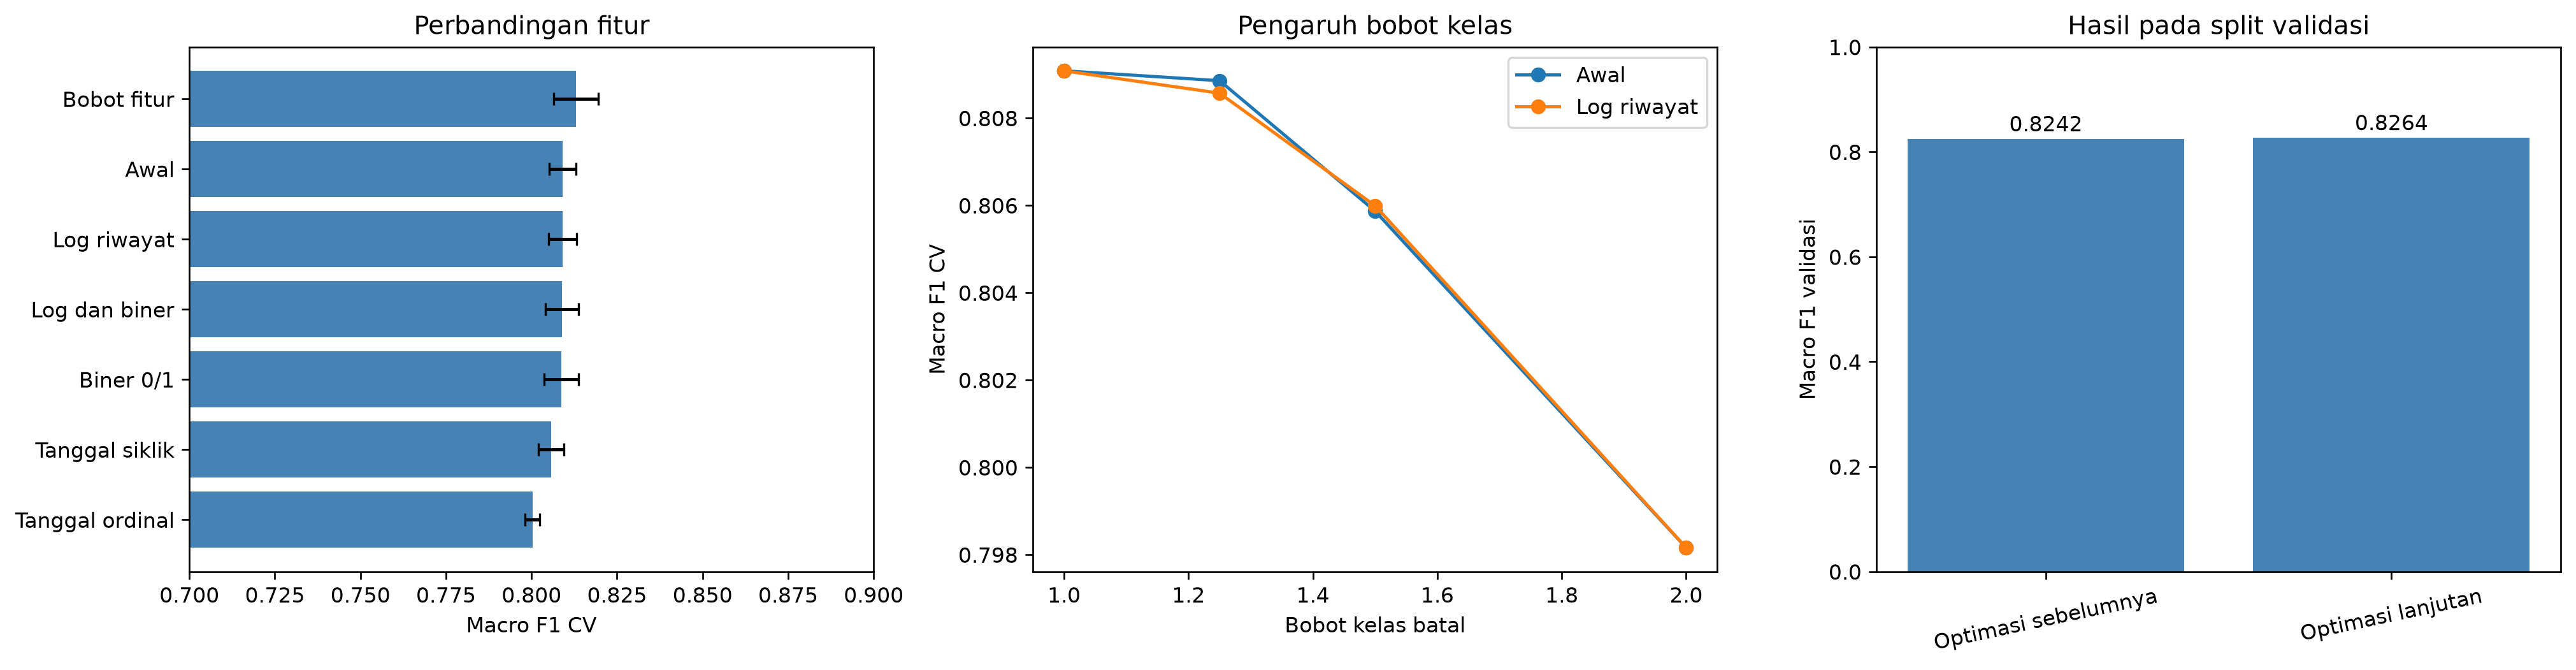

In [145]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
feature_plot = svm_refine_features.sort_values('cv_macro_f1')
axes[0].barh(feature_plot['features'], feature_plot['cv_macro_f1'],
             xerr=feature_plot['cv_std'], color=CFG.PLOT_COLOR, capsize=3)
axes[0].set(xlabel='Macro F1 CV', title='Perbandingan fitur', xlim=(0.7, 0.9))
for features, rows in svm_refine_weights.groupby('features', sort=False):
    rows = rows.sort_values('weight')
    axes[1].plot(rows['weight'], rows['cv_macro_f1'], marker='o', label=features)
axes[1].set(xlabel='Bobot kelas batal', ylabel='Macro F1 CV', title='Pengaruh bobot kelas')
axes[1].legend()
axes[2].bar(svm_refine_validation['model'], svm_refine_validation['macro_f1'], color=CFG.PLOT_COLOR)
axes[2].set(ylabel='Macro F1 validasi', title='Hasil pada split validasi', ylim=(0, 1))
axes[2].tick_params(axis='x', labelrotation=12)
for index, score in enumerate(svm_refine_validation['macro_f1']):
    axes[2].text(index, score + 0.015, f'{score:.4f}', ha='center')
fig.tight_layout()
plt.show()

In [146]:
svm_refined_final_preprocessor = make_svm_refine_preprocessor(svm_refine_best['features']).fit(full_train)
svm_refined_final = SVM(C=svm_refined.C, kernel='gaussian', gamma=svm_refined.gamma,
                        class_weight=svm_refined.class_weight, decision_threshold=0.0,
                        tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_refined_final.fit(svm_refined_final_preprocessor.transform(full_train),
                      full_train[TARGET].to_numpy())
if not svm_refined_final.converged_:
    raise RuntimeError('SVM final lanjutan belum konvergen.')
svm_refined_test_pred = svm_refined_final.predict(svm_refined_final_preprocessor.transform(test_df))
svm_refined_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': svm_refined_test_pred.astype(int)})
assert svm_refined_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_refined_submission['id'].equals(sample_submission['id'])
assert len(svm_refined_submission) == len(test_df) and svm_refined_submission['id'].is_unique
assert set(svm_refined_submission['is_canceled'].unique()) <= {0, 1}
svm_refined_submission_path = CFG.OUTPUT_DIR / 'submission_svm_refined.csv'
svm_refined_submission.to_csv(svm_refined_submission_path, index=False)
svm_refined_final.save(CFG.MODEL_DIR / 'svm_refined_final.pkl')
svm_refined_final_preprocessor.save(CFG.MODEL_DIR / 'svm_refined_preprocessor_final.pkl')
svm_refine_final_loaded = SVM.load(CFG.MODEL_DIR / 'svm_refined_final.pkl')
svm_refine_final_prep_loaded = Preprocessor.load(CFG.MODEL_DIR / 'svm_refined_preprocessor_final.pkl')
assert np.array_equal(svm_refine_final_loaded.predict(svm_refine_final_prep_loaded.transform(test_df)),
                      svm_refined_test_pred)
print(svm_refined_submission_path, svm_refined_submission.shape)
svm_refined_submission.head()

C:\Projects\IF3170_G25_IMKSIAI\output\submission_svm_refined.csv (6844, 2)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


**Hasil dan pembahasan:**

CV pada seluruh training split memilih pembobotan fitur dengan C sekitar 16.02, gamma 0.06084, bobot kelas batal 1, dan ambang keputusan nol. Macro F1 CV naik dari 0.8211 menjadi 0.8249. Pada split validasi lama, Macro F1 naik dari 0.8242 menjadi 0.8264, dengan selisih +0.0022.

Peningkatan berasal dari pembobotan fitur. Transformasi log riwayat dan fitur biner 0/1 belum memberi peningkatan yang konsisten pada parameter awal. Penggantian representasi tanggal dan bobot kelas yang lebih besar menurunkan CV pada percobaan tersebut. Pencarian DE lanjutan juga belum melampaui konfigurasi sebelumnya, sedangkan pembobotan fitur menghasilkan kandidat yang lebih baik.

Model terpilih dilatih ulang pada seluruh data training yang sudah dibersihkan.CV digunakan untuk pemilihan konfigurasi. Split validasi sudah pernah digunakan sebelumnya, sehingga hasil ini belum menjadi estimasi independen. Skor leaderboard submission baru belum diketahui.